<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">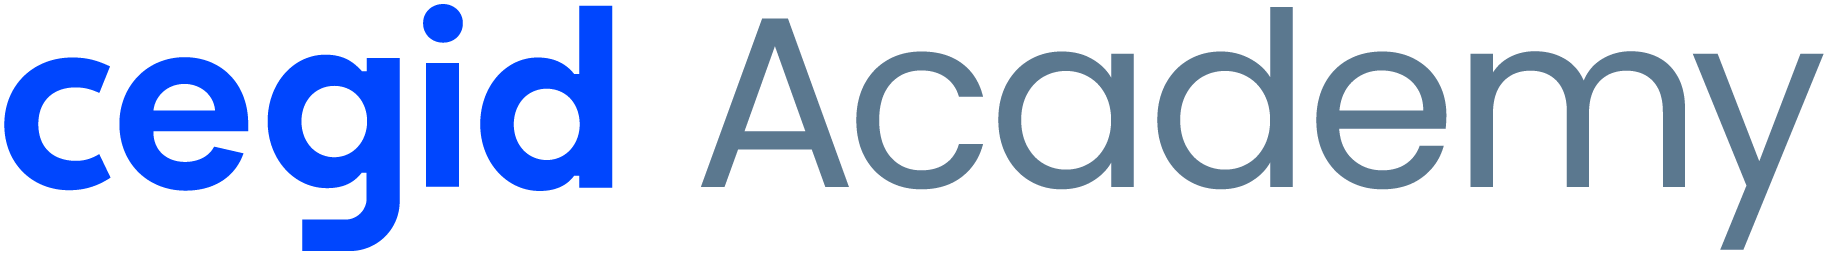<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 3 &middot; Preparação dos Dados</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Data Preparation</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M3.01 · M3.02</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** |  |
| **Grupo** | |
| **Formandos** | |
| **Data** | |
| **Dataset** | |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Transformar dados brutos em dados <b>modeláveis</b>: garantir qualidade, reduzir ruído e evitar enviesamentos. É tipicamente a fase que consome <b>60–80% do tempo</b> do projeto. Todas as decisões devem vir da síntese da Fase 2.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Data leakage</div><b>Regra de ouro contra o <i>data leakage</i>:</b> qualquer transformação que <b>aprende parâmetros</b> dos dados (média/mediana da imputação, categorias do encoding, média e desvio do scaling, componentes do PCA, limites de outliers, target encoding) deve ser ajustada <b>apenas no conjunto de treino</b> e depois aplicada ao teste. Por isso, a divisão treino/teste é feita <b>antes</b> dessas transformações.</div>

**Ordem recomendada (M3)**

1. Seleção de dados → 2. Limpeza determinística → 3. **Separação treino/teste** → 4. Feature engineering → 5. Valores em falta → 6. Outliers → 7. Encoding → 8. Scaling → 9. Redução de dimensionalidade → 10. Pipeline final → 11. Exportação

### 0. Configuração
<hr>

Usar **a mesma configuração** do notebook 02.

**0.1 Bibliotecas**
- `numpy`, `pandas`, `matplotlib`, `seaborn`, `json`, `pathlib`.
- Do scikit-learn: `train_test_split`, encoders (`OneHotEncoder`, `LabelEncoder`, `OrdinalEncoder`), scalers, imputers (`SimpleImputer`, `KNNImputer`), seleção (`VarianceThreshold`, `SelectKBest`, `RFE`), `PCA`, `Pipeline` e `ColumnTransformer`.

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, RFE
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression  # estimador usado pelo RFE
from sklearn.decomposition import PCA

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


Bibliotecas carregadas.


**0.2 Configuração do projeto** — os **mesmos** valores do notebook 02 (`PROJETO`, `DATA_PATH`, `TARGET`, `PROBLEM_TYPE`, `ID_COLS`, `RANDOM_STATE`, `TEST_SIZE`).

In [4]:
PROJETO = "HR-Job-Change"
DATA_PATH = "Data/input/Dados_RH_Mudanca_Emprego.csv"
TARGET = "procura_mudanca_emprego"
PROBLEM_TYPE = "classificacao" 
ID_COLS = ["id_candidato"]
RANDOM_STATE = 42
TEST_SIZE = 0.2

df = pd.read_csv(DATA_PATH)
print(df.shape)  

(19158, 14)


**0.3 Estrutura de pastas** — igual ao notebook 02 (`Data/input`, `Data/output`, `Data/analytics`, `Data/models`).

In [5]:
PASTAS = ["Data/input", "Data/output", "Data/analytics", "Data/models"]
for pasta in PASTAS:
    Path(pasta).mkdir(parents=True, exist_ok=True)

def guardar_figura(nome):
    caminho = Path("Data/analytics") / f"{nome}.png"
    plt.savefig(caminho, dpi=150, bbox_inches="tight")
    print(f"Figura guardada em: {caminho}")

**0.4 Carregar os dados**
- Ler o dataset original para `df_raw` e trabalhar numa cópia `df` (o original nunca é alterado).

In [6]:
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

# Cópia de trabalho: todas as alterações são feitas aqui
df = df_raw.copy()

# Verificações rápidas
print("Dimensão:", df.shape)            # esperado: (19158, 14)
print("\nColunas:", df.columns.tolist())
print("\nDistribuição do target:")
print(df[TARGET].value_counts(normalize=True).round(3))

df.head()

Dimensão: (19158, 14)

Colunas: ['id_candidato', 'cidade', 'indice_desenvolvimento_cidade', 'genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'anos_experiencia', 'dimensao_empresa', 'tipo_empresa', 'anos_desde_ultimo_emprego', 'horas_formacao', 'procura_mudanca_emprego']

Distribuição do target:
procura_mudanca_emprego
Não    0.751
Sim    0.249
Name: proportion, dtype: float64


,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,500 a 999,Empresa privada,1 ano,21,Não
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,Mais de 20 anos,100 a 500,Startup financiada,2 anos,74,Não
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,10 a 49,Empresa privada,1 ano,94,Não
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,10000 ou mais,Empresa privada,1 ano,75,Não
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",12 anos,500 a 999,ONG,1 ano,157,Não


### 1. Seleção de dados
<hr>

**Descrever que dados serão utilizados no modelo:**

- Que variáveis serão consideradas? Quais serão removidas e porquê?
- Colunas irrelevantes (identificadores, texto livre sem valor, colunas constantes)?
- Variáveis redundantes (a mesma informação noutra forma, ex.: `Attrition` e `AttritionFlag`)?
- Variáveis que **revelam o target** ou que não existiriam no momento da previsão (*leakage*)?
- O dataset será filtrado (por país, período, categoria)?

***Objetivo:*** definir claramente o subconjunto de dados a utilizar.

**1.1 Seleção de dados**
- Remover as colunas irrelevantes, redundantes ou que revelam o alvo (decididas na Fase 2) — `drop(columns=...)`.
- Aplicar filtros de linhas, se fizer sentido.
- Os identificadores (`ID_COLS`) podem ficar no DataFrame para rastreabilidade, mas não vão entrar no modelo.

In [7]:
# 1. Confirmar a redundância cidade ↔ índice (cada cidade tem um único índice)
indices_por_cidade = df.groupby("cidade")["indice_desenvolvimento_cidade"].nunique()
print("Cidades com mais de um índice:", (indices_por_cidade > 1).sum())  # esperado: 0



Cidades com mais de um índice: 0


In [ ]:
# 2. Colunas a remover (decididas na Fase 2)
COLS_REMOVER = ["cidade"]  # redundante com indice_desenvolvimento_cidade; 123 categorias

df = df.drop(columns=COLS_REMOVER)


In [9]:
# 3. Filtros de linhas: nenhum (ver justificação na resposta)

# 4. Definir as features: tudo exceto ID e target
FEATURES = [c for c in df.columns if c not in ID_COLS + [TARGET]]

print("\nDimensão após seleção:", df.shape)  # esperado: (19158, 13)
print(f"\nFeatures ({len(FEATURES)}):", FEATURES)
print("\nFicam no DataFrame mas fora do modelo:", ID_COLS + [TARGET])


Dimensão após seleção: (19158, 13)

Features (11): ['indice_desenvolvimento_cidade', 'genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'anos_experiencia', 'dimensao_empresa', 'tipo_empresa', 'anos_desde_ultimo_emprego', 'horas_formacao']

Ficam no DataFrame mas fora do modelo: ['id_candidato', 'procura_mudanca_emprego']


##### Análise e Interpretação

> *Que variáveis foram removidas e porquê?*

**Resposta:**

- Removida: `cidade`é redundante com `indice_desenvolvimento_cidade`: cada cidade tem sempre o mesmo índice (verificado: 0 cidades com mais de um valor). Além disso tem 123 categorias, 106 delas com menos de 1% das linhas (secção 4), o que daria origem a muitas colunas no one-hot encoding e a categorias com poucos exemplos (24,8% das células com frequência esperada < 5 no qui-quadrado, secção 5.5.3). O índice guarda a informação essencial (r = -0,34 com o alvo; d de Cohen ≈ -0,84) numa única coluna numérica
- Mantida mas fora do modelo: `id_candidato` é um identificador único, sem valor preditivo. Fica no DataFrame para rastreabilidade (permite voltar a identificar cada candidato), mas é excluída da lista de features
- não foram removidas variáveis por data leakage, porque nenhuma revela o target nem seria desconhecida no momento da previsão (Fase 2, secção 7).
- Variáveis fracas mantidas: `horas_formacao`, `genero` e `area_formacao` têm efeito pequeno, mas são mantidas numa primeira versão
- Sem filtros de linhas: não existe país, período ou categoria que justifique excluir candidatos, e remover linhas com nulos eliminaria 53,3% dos dados e informação útil (a falta de dados está associada ao alvo).

- Resultado: 19 158 linhas, 11 features + `id_candidato` + target.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Exemplo HR (regressão de <code>MonthlyIncome</code>): foram removidos <code>EmployeeID</code> (identificador), <code>Attrition</code> (redundante) e <code>AttritionFlag</code> (rótulo de saída que enviesaria a estimação salarial).</div>

### 2. Limpeza determinística (antes da divisão)
<hr>

Correções que **não aprendem nada com os dados** e podem ser feitas no dataset completo:

- **Duplicados**: remover os que são erros de registo
- **Tipos de dados**: converter texto para número/data, números para categoria
- **String processing**: remover espaços, uniformizar maiúsculas/minúsculas, corrigir categorias
- **Date/Time processing**: extrair ano, mês, dia da semana, fim de semana, diferenças entre datas
- **Códigos de missing disfarçados** (999, −1, `0` impossível) → `NaN` verdadeiro
- **Colunas redundantes**: a mesma informação noutra forma — e atenção a variáveis que são o **alvo disfarçado** (no Titanic, `alive`) → removê-las é prevenção de *leakage*
- **Inconsistências**: valores impossíveis (negativos, % > 100) → `NaN`
- **Target**: garantir que está codificado (ex.: `"Yes"/"No"` → `1/0`)

> **Determinística** = regra fixa definida por vocês (ex.: `999 → NaN`, `"hr " → "HR"`). Se a regra usa uma estatística dos dados (mediana, quantis, frequências, data mínima do dataset), deixa de ser determinística e passa para depois da divisão.

***Objetivo:*** garantir qualidade e coerência dos dados.

**2.1 Duplicados**
- Remover duplicados (`drop_duplicates`) e indicar quantos foram removidos.

In [10]:
# já tinhamos visto que não há duplicados 

n_antes = len(df)

# 1. Duplicados exatos (todas as colunas, incluindo o ID)
print("Linhas duplicadas (com ID):", df.duplicated().sum())        

# 2. IDs repetidos
print("IDs repetidos:", df["id_candidato"].duplicated().sum()) 

# 3. Duplicados ignorando o ID (perfis iguais)
cols_sem_id = [c for c in df.columns if c not in ID_COLS]
n_dup_sem_id = df.duplicated(subset=cols_sem_id).sum()
print("Linhas iguais ignorando o ID:", n_dup_sem_id)

# 4. Remover apenas duplicados exatos (erros de registo)
df = df.drop_duplicates()

n_depois = len(df)
print(f"\nLinhas antes: {n_antes} | depois: {n_depois} | removidas: {n_antes - n_depois}")

Linhas duplicadas (com ID): 0
IDs repetidos: 0
Linhas iguais ignorando o ID: 60

Linhas antes: 19158 | depois: 19158 | removidas: 0


In [11]:
df[df.duplicated(subset=cols_sem_id, keep=False)].sort_values(cols_sem_id).head(10)

,id_candidato,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
627,379167,0.624,Masculino,Com experiência relevante,Curso a tempo inteiro,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",5 anos,10000 ou mais,Empresa privada,1 ano,12,Sim
993,605422,0.624,Masculino,Com experiência relevante,Curso a tempo inteiro,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",5 anos,10000 ou mais,Empresa privada,1 ano,12,Sim
14440,416814,0.624,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,100 a 500,Empresa privada,Nunca,2,Sim
16119,260244,0.624,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,100 a 500,Empresa privada,Nunca,2,Sim
5253,771726,0.624,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",7 anos,100 a 500,Empresa privada,2 anos,6,Sim
10947,960406,0.624,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",7 anos,100 a 500,Empresa privada,2 anos,6,Sim
486,280429,0.624,Masculino,Sem experiência relevante,Curso a tempo inteiro,Ensino Secundário,NaN,2 anos,NaN,NaN,Nunca,28,Sim
3551,986376,0.624,Masculino,Sem experiência relevante,Curso a tempo inteiro,Ensino Secundário,NaN,2 anos,NaN,NaN,Nunca,28,Sim
7694,601366,0.624,Masculino,Sem experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",Menos de 1 ano,NaN,NaN,1 ano,14,Sim
15800,726358,0.624,Masculino,Sem experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",Menos de 1 ano,NaN,NaN,1 ano,14,Sim


##### Análise e Interpretação

> *Os duplicados eram erros? Quantos foram removidos?*

**Resposta:**

- Duplicados exatos: 0 não existem linhas repetidas nem IDs repetidos (confirmado também na Fase 2, secção 3.3). O `drop_duplicates()` foi aplicado por segurança, mas removeu 0 linhas (19 158 antes e depois).
- Perfis iguais ignorando o ID: 60 linhas (49 na Fase 2, com a `cidade` incluída; o número aumenta ligeiramente após a remoção da `cidade`). Não são erros de registo: têm `id_candidato` diferentes, ou seja, são candidatos distintos que por acaso têm as mesmas respostas. Com variáveis maioritariamente categóricas e poucas categorias, é normal que pessoas diferentes tenham o mesmo perfil (ex.: homem, STEM, licenciado, 5 anos de experiência...)
- Decisão: manter estas linhas. Removê-las apagaria candidatos reais e alteraria a distribuição dos dados

<hr>

**2.2 String processing (M3.01)**
- Nas variáveis de texto: remover espaços (`str.strip`), espaços repetidos (`str.replace(r"\s+", " ", regex=True)`), uniformizar maiúsculas/minúsculas e corrigir categorias escritas de formas diferentes (`replace`).
- (Se aplicável) extrair informação com regex (`str.extract`).

In [12]:
# tb já tinhamos visto que não havia alterações

cat_cols = df.select_dtypes(exclude="number").columns.drop(TARGET).tolist()
# (o target também é texto, mas tratamo-lo à parte na secção do target)

resumo = []
for col in cat_cols + [TARGET]:
    n_antes = df[col].nunique()

    # 1. Remover espaços no início/fim e espaços repetidos
    df[col] = (df[col]
               .str.strip()
               .str.replace(r"\s+", " ", regex=True))

    n_depois = df[col].nunique()

    # 2. Teste: se ignorarmos maiúsculas/minúsculas, surgem categorias "iguais"?
    n_lower = df[col].str.lower().nunique()

    resumo.append({
        "coluna": col,
        "categorias_antes": n_antes,
        "depois_strip": n_depois,
        "se_minusculas": n_lower,
        "alterou": n_antes != n_depois or n_depois != n_lower
    })

resumo_df = pd.DataFrame(resumo)
resumo_df

,coluna,categorias_antes,depois_strip,se_minusculas,alterou
0,genero,3,3,3,False
1,experiencia_relevante,2,2,2,False
2,inscricao_universidade,3,3,3,False
3,nivel_educacao,5,5,5,False
4,area_formacao,6,6,6,False
5,anos_experiencia,22,22,22,False
6,dimensao_empresa,8,8,8,False
7,tipo_empresa,6,6,6,False
8,anos_desde_ultimo_emprego,6,6,6,False
9,procura_mudanca_emprego,2,2,2,False


##### Análise e Interpretação

> *Que correções de texto foram necessárias?*

**Resposta:**

- foi aplicada, a todas as variáveis de texto (9 features categóricas + target), a remoção de espaços no início/fim (`str.strip`) e de espaços repetidos (`str.replace(r"\s+", " ")`)
- nenhuma correção foi efetivamente necessária: o número de categorias distintas manteve-se igual em todas as colunas antes e depois da limpeza, e uniformizar para minúsculas também não juntaria nenhuma categoria. Não há categorias escritas de formas diferentes, pelo que não foi preciso usar `replace` para as unificar (confirma a secção 3.5 da Fase 2).
- os valores em falta (`NaN`) não foram alterados pela limpeza;
- Extração com regex: as colunas `anos_experiencia` e `anos_desde_ultimo_emprego` contêm números escritos como texto ("Menos de 1 ano", "Mais de 20 anos", "Nunca"). Em vez de `str.extract`, serão convertidas para numéricas com um mapeamento explícito na secção de tipos de dados, porque alguns valores exigem regras específicas.

<hr>

**2.3 Tipos de dados e datas (M3.01)**
- Converter tipos errados (`pd.to_datetime`, `astype`).
- Se houver datas: criar ano, mês, dia da semana, fim de semana, dias desde uma data de referência **fixa** (ex.: a data de início do contrato — não a data mínima do dataset) (`.dt`).

In [13]:
# não temos datas mas podemos já converter as colunas com "anos" que estão como texto para numeros

for col in ["anos_experiencia", "anos_desde_ultimo_emprego"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False), "\n")

--- anos_experiencia ---
anos_experiencia
Mais de 20 anos    3286
5 anos             1430
4 anos             1403
3 anos             1354
6 anos             1216
2 anos             1127
7 anos             1028
10 anos             985
9 anos              980
8 anos              802
15 anos             686
11 anos             664
14 anos             586
1 ano               549
Menos de 1 ano      522
16 anos             508
12 anos             494
13 anos             399
17 anos             342
19 anos             304
18 anos             280
20 anos             148
NaN                  65
Name: count, dtype: int64 

--- anos_desde_ultimo_emprego ---
anos_desde_ultimo_emprego
1 ano             8040
Mais de 4 anos    3290
2 anos            2900
Nunca             2452
4 anos            1029
3 anos            1024
NaN                423
Name: count, dtype: int64 



In [14]:
def converter_anos(serie, especiais):
    """Converte texto de anos para número.
    1) aplica o dicionário de casos especiais;
    2) nos restantes, extrai o primeiro número do texto."""
    numeros = serie.str.extract(r"(\d+)")[0]          # ex.: "5" ou "5 anos" -> "5"
    resultado = serie.map(especiais)                   # casos especiais -> número
    resultado = resultado.fillna(pd.to_numeric(numeros, errors="coerce"))
    return resultado.astype("float")                   # float porque há NaN

# Ajusta as chaves ao texto EXATO que viste no passo 1
ESPECIAIS_EXPERIENCIA = {
    "Menos de 1 ano": 0,
    "Mais de 20 anos": 21,
}
ESPECIAIS_ULTIMO_EMPREGO = {
    "Nunca": 0,
    "Mais de 4 anos": 5,
}

for col, especiais in [("anos_experiencia", ESPECIAIS_EXPERIENCIA),
                       ("anos_desde_ultimo_emprego", ESPECIAIS_ULTIMO_EMPREGO)]:
    nulos_antes = df[col].isna().sum()
    df[col] = converter_anos(df[col], especiais)
    nulos_depois = df[col].isna().sum()
    print(f"{col}: tipo = {df[col].dtype} | nulos antes = {nulos_antes} | depois = {nulos_depois}")

anos_experiencia: tipo = float64 | nulos antes = 65 | depois = 65
anos_desde_ultimo_emprego: tipo = float64 | nulos antes = 423 | depois = 423


In [15]:
# Mostra os textos originais que ficaram NaN sem o serem antes
col = "anos_experiencia"
falhas = df_raw.loc[df[col].isna() & df_raw[col].notna(), col].unique()
print(falhas)

<StringArray>
[]
Length: 0, dtype: str


In [16]:
print(df[["anos_experiencia", "anos_desde_ultimo_emprego"]].describe())

print("\nTaxa de 'Sim' por anos de experiência (deve descer, como na Fase 2):")
print(df.groupby("anos_experiencia")[TARGET]
        .apply(lambda s: (s == "Sim").mean())
        .round(3))

       anos_experiencia  anos_desde_ultimo_emprego
count      19093.000000               18735.000000
mean          10.100141                   2.000427
std            6.777024                   1.675596
min            0.000000                   0.000000
25%            4.000000                   1.000000
50%            9.000000                   1.000000
75%           16.000000                   3.000000
max           21.000000                   5.000000

Taxa de 'Sim' por anos de experiência (deve descer, como na Fase 2):
anos_experiencia
0.0     0.454
1.0     0.424
2.0     0.332
3.0     0.353
4.0     0.326
5.0     0.288
6.0     0.282
7.0     0.295
8.0     0.243
9.0     0.217
10.0    0.210
11.0    0.227
12.0    0.186
13.0    0.193
14.0    0.183
15.0    0.166
16.0    0.142
17.0    0.167
18.0    0.154
19.0    0.174
20.0    0.223
21.0    0.153
Name: procura_mudanca_emprego, dtype: float64


##### Análise e Interpretação

> *Que conversões foram feitas? As novas variáveis temporais fazem sentido para o problema?*

**Resposta:**

- Conversões feitas: `anos_experiencia` e `anos_desde_ultimo_emprego` estavam guardadas como texto, embora representem quantidades. Foram convertidas para numéricas (`float`, porque mantêm valores em falta):
  - `anos_experiencia`: "Menos de 1 ano" → 0; "Mais de 20 anos" → 21; restantes valores → o número indicado (1 a 20)
  - `anos_desde_ultimo_emprego`: "Nunca" → 0; "Mais de 4 anos" → 5; restantes → o número indicado (1 a 4)
- Justificação dos valores especiais: os limites abertos ("Mais de 20", "Mais de 4") foram codificados como o valor seguinte (21 e 5), para manter a ordem sem inventar um valor exato. "Menos de 1 ano" e "Nunca" foram codificados como 0 (nenhum ano de experiência / nunca mudou de emprego)
- Verificação: o número de nulos manteve-se igual antes e depois da conversão (nenhum texto ficou por converter); os nulos originais (0,34% e 2,21%) serão tratados depois da divisão treino/teste. A relação com o alvo manteve-se: a taxa de "Sim" desce à medida que os anos de experiência aumentam
- Porque converter: como números, os modelos passam a usar a ordem (5 anos < 10 anos) e evitam-se 22 colunas de one-hot para `anos_experiencia`.
- Datas: o dataset não tem variáveis de data nem informação temporal, pelo que não foram criadas variáveis temporais (ano, mês, dia da semana, etc.). `anos_desde_ultimo_emprego` já é, ela própria, uma medida de tempo.
- `dimensao_empresa` e `nivel_educacao` mantêm-se como texto nesta fase; serão codificadas como ordinais na secção de encoding, depois da divisão.

<hr>

**2.4 Códigos de missing e inconsistências (M3.01)**
- Converter códigos de missing disfarçados (999, −1, 0 impossível) e valores impossíveis em `np.nan`.

In [17]:
# já tinhamos visto antes que não temos valores impossíveis

# 1. Regras de validade (definidas por nós, fixas = determinísticas)
REGRAS_VALIDAS = {
    "indice_desenvolvimento_cidade": (0, 1),    # é um índice entre 0 e 1
    "horas_formacao":                (1, 1000), # horas positivas; >1000 seria implausível
    "anos_experiencia":              (0, 21),   # 0 = "Menos de 1 ano"; 21 = "Mais de 20"
    "anos_desde_ultimo_emprego":     (0, 5),    # 0 = "Nunca"; 5 = "Mais de 4"
}
CODIGOS_MISSING = [999, 9999, -1, -999]

resumo = []
for col, (minimo, maximo) in REGRAS_VALIDAS.items():
    nulos_antes = df[col].isna().sum()

    # Códigos disfarçados -> NaN
    df.loc[df[col].isin(CODIGOS_MISSING), col] = np.nan
    # Fora do intervalo válido -> NaN
    df.loc[(df[col] < minimo) | (df[col] > maximo), col] = np.nan

    resumo.append({
        "coluna": col,
        "min": df[col].min(), "max": df[col].max(),
        "convertidos_em_nulo": df[col].isna().sum() - nulos_antes
    })

pd.DataFrame(resumo)

,coluna,min,max,convertidos_em_nulo
0,indice_desenvolvimento_cidade,0.448,0.949,0
1,horas_formacao,1.000,336.000,0
2,anos_experiencia,0.000,21.000,0
3,anos_desde_ultimo_emprego,0.000,5.000,0


In [18]:
# 2. Missing disfarçado nas categóricas (texto que significa "não sei")
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
TEXTOS_MISSING = ["", "-", "?", "n/a", "na", "nan", "none", "null",
                  "desconhecido", "sem informação", "não sabe"]

for col in cat_cols:
    suspeitos = df[col].dropna().str.lower().isin(TEXTOS_MISSING).sum()
    print(f"{col}: {suspeitos} valores suspeitos")

genero: 0 valores suspeitos
experiencia_relevante: 0 valores suspeitos
inscricao_universidade: 0 valores suspeitos
nivel_educacao: 0 valores suspeitos
area_formacao: 0 valores suspeitos
dimensao_empresa: 0 valores suspeitos
tipo_empresa: 0 valores suspeitos
procura_mudanca_emprego: 0 valores suspeitos


In [19]:
# 3. Coerência entre colunas (só para relatar, não converter)
incoerentes = df[df["anos_desde_ultimo_emprego"] > df["anos_experiencia"] + 1]
print("Casos com mais anos desde o último emprego do que de experiência:", len(incoerentes))
incoerentes[["anos_experiencia", "anos_desde_ultimo_emprego"]].value_counts().head()

Casos com mais anos desde o último emprego do que de experiência: 116


anos_experiencia  anos_desde_ultimo_emprego
0.0               2.0                          44
3.0               5.0                          35
0.0               5.0                          21
                  3.0                           8
                  4.0                           8
Name: count, dtype: int64

##### Análise e Interpretação

> *Que valores foram convertidos em nulos e porquê?*

**Resposta:**

- Nenhum valor foi convertido em nulo. Foram definidas regras de validade fixas para as 4 variáveis numéricas (`indice_desenvolvimento_cidade` entre 0 e 1; `horas_formacao` entre 1 e 1000; `anos_experiencia` entre 0 e 21; `anos_desde_ultimo_emprego` entre 0 e 5) e procurados códigos típicos de missing disfarçado (999, 9999, -1, -999). Todos os valores estão dentro dos limites e não há códigos disfarçados (confirma a secção 3.4 da Fase 2).
- Categóricas: não há textos que signifiquem "valor desconhecido" ("-", "?", "N/A", vazio...). A categoria "Outro" foi mantida porque é uma resposta válida e não um valor em falta.
- Coerência entre colunas: foram encontrados 116 casos em que os anos desde o último emprego são superiores aos anos de experiência. Não foram convertidos em nulos, porque o significado exato das variáveis não é conhecido (podem existir pausas na carreira ou a experiência pode referir-se só à área relevante); ficam registados como observação.
- Os nulos que existem são os originais (ex.: `tipo_empresa` 32,05%), tratados como informativos e preenchidos depois da divisão treino/teste.


<hr>

**2.5 [Classificação] Codificar o alvo**
- Se o target estiver em texto, convertê-lo em números com `LabelEncoder` e mostrar o mapeamento (`classes_`).
- Garantir que a **classe de interesse** (a que se quer detetar: sair, fraude, doença…) fica codificada como `1`: precision, recall e F1 usam `pos_label=1` por omissão. O `LabelEncoder` ordena alfabeticamente — em binário, um `map` explícito (ex.: `{"No": 0, "Yes": 1}`) é mais seguro.

In [20]:
# 1. Confirmar os valores do target antes de codificar
print("Valores do target:", df[TARGET].unique())
print(df[TARGET].value_counts(), "\n")

# 2. Versão "de demonstração": LabelEncoder (ordem alfabética)
le = LabelEncoder()
le.fit(df[TARGET])
print("LabelEncoder - classes_:", le.classes_)  # posição 0 = 'Não', posição 1 = 'Sim'
print("Mapeamento:", dict(zip(le.classes_, le.transform(le.classes_))), "\n")

# 3. Versão usada: map explícito (a classe de interesse fica em 1, de certeza)
MAPA_TARGET = {"Não": 0, "Sim": 1}
df[TARGET] = df[TARGET].map(MAPA_TARGET)

# 4. Verificações
print("Nulos no target após codificação:", df[TARGET].isna().sum())  # tem de dar 0
print("Tipo:", df[TARGET].dtype)
print(df[TARGET].value_counts())
print("\nProporção de 1 (Sim):", round(df[TARGET].mean(), 3))      # esperado: ~0.249

Valores do target: <StringArray>
['Não', 'Sim']
Length: 2, dtype: str
procura_mudanca_emprego
Não    14381
Sim     4777
Name: count, dtype: int64 

LabelEncoder - classes_: ['Não' 'Sim']
Mapeamento: {'Não': np.int64(0), 'Sim': np.int64(1)} 

Nulos no target após codificação: 0
Tipo: int64
procura_mudanca_emprego
0    14381
1     4777
Name: count, dtype: int64

Proporção de 1 (Sim): 0.249


- O target `procura_mudanca_emprego` estava em texto ("Sim"/"Não") e foi convertido para numérico com um mapeamento explícito: Não = 0 e Sim = 1
- A classe de interesse é "Sim" (o candidato procura mudar de emprego), porque é a que a empresa quer detetar. Ficou codificada como 1, que é a classe positiva que as métricas (precision, recall, F1) usam por omissão (`pos_label=1`).
- O `LabelEncoder` daria o mesmo resultado (ordena alfabeticamente: "Não" < "Sim"), mas o `map` explícito foi preferido por ser mais seguro e legível: a codificação não depende da ordem alfabética.
- Verificação: nenhum valor ficou por codificar (0 nulos); as contagens mantêm-se (14 381 zeros e 4 777 uns), e a média do target, 0,249, corresponde à taxa de "Sim".

### 3. Separação dos dados (treino / teste)
<hr>

- Proporção: 80/20 ou 70/30 (compromisso entre dados para aprender e dados para validar)
- `random_state` → reprodutibilidade
- `stratify=y` em classificação → mantém a proporção das classes em treino e teste
- O **conjunto de teste fica "intocado"** até à avaliação do modelo final (Fase 4, secção 7, e Fase 5): não é usado para escolher variáveis, estratégias de preparação, modelos, hiperparâmetros ou limiares
- **Dados temporais** → divisão cronológica (dados ordenados por data e `shuffle=False`, ou corte por data) em vez de aleatória
- **Várias linhas por entidade** → divisão por grupo (`GroupShuffleSplit`), para a mesma entidade não ficar no treino e no teste
- A validação cruzada é feita na Fase 4, **apenas com o treino**

***Objetivo:*** garantir uma avaliação justa e evitar *data leakage*.

**3.1 [Classificação / Regressão] Separar X e y e dividir treino/teste**
- `X` = todas as colunas exceto o target; `y` = target.
- `train_test_split` com `test_size=TEST_SIZE`, `random_state=RANDOM_STATE` e `stratify=y` em classificação.
- Mostrar as dimensões de `X_train` e `X_test`.

In [23]:
# 1. Separar X e y
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("X:", X.shape, "| y:", y.shape)   # esperado: (19158, 11) | (19158,)



X: (19158, 11) | y: (19158,)


In [ ]:
# 2. Dividir treino/teste (80/20, estratificado)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,          # 0.2
    random_state=RANDOM_STATE,    # 42
    stratify=y                    # mesma proporção de 0/1 nos dois conjuntos
)

print("\nX_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)




X_train: (15326, 11) | y_train: (15326,)
X_test:  (3832, 11) | y_test:  (3832,)


In [29]:
# 3. Confirmar a estratificação
proporcoes = pd.DataFrame({
    "Total":  y.value_counts(normalize=True),
    "Treino": y_train.value_counts(normalize=True),
    "Teste":  y_test.value_counts(normalize=True),
}).round(3)
proporcoes.index = ["0 (Não)", "1 (Sim)"]
proporcoes

,Total,Treino,Teste
0 (Não),0.751,0.751,0.751
1 (Sim),0.249,0.249,0.249


**3.2 [Classificação] Verificar a estratificação**
- Comparar a proporção das classes no dataset, no treino e no teste.

In [ ]:
# 1. Tabela com contagens e proporções em cada conjunto
conjuntos = {"Total": y, "Treino": y_train, "Teste": y_test}

tabela = pd.DataFrame({
    nome: {
        "n_linhas": len(serie),
        "n_Não (0)": (serie == 0).sum(),
        "n_Sim (1)": (serie == 1).sum(),
        "% Sim (1)": round(serie.mean() * 100, 2),
    }
    for nome, serie in conjuntos.items()
}).T

print(tabela)

        n_linhas  n_Não (0)  n_Sim (1)  % Sim (1)
Total    19158.0    14381.0     4777.0      24.93
Treino   15326.0    11504.0     3822.0      24.94
Teste     3832.0     2877.0      955.0      24.92



Diferença máxima de % Sim entre conjuntos: 0.02 p.p.
Figura guardada em: Data\analytics\03_estratificacao_treino_teste.png


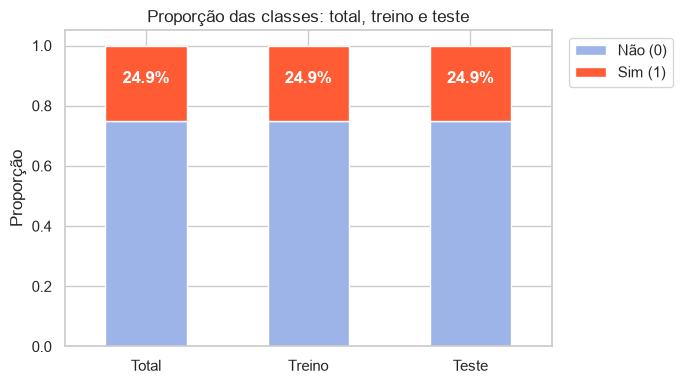

In [32]:
# 2. Diferença máxima de % Sim entre conjuntos (em pontos percentuais)
dif = tabela["% Sim (1)"].max() - tabela["% Sim (1)"].min()
print(f"\nDiferença máxima de % Sim entre conjuntos: {dif:.2f} p.p.")

# 3. Gráfico: proporção de cada classe por conjunto
props = pd.DataFrame({
    nome: serie.value_counts(normalize=True).sort_index()
    for nome, serie in conjuntos.items()
}).T
props.columns = ["Não (0)", "Sim (1)"]

ax = props.plot(kind="bar", stacked=True, figsize=(7, 4), color=["#9DB4E8", "#FF5B34"])
ax.set_ylabel("Proporção")
ax.set_title("Proporção das classes: total, treino e teste")
ax.set_xticklabels(props.index, rotation=0)
for i, v in enumerate(props["Sim (1)"]):
    ax.text(i, 1 - v / 2, f"{v:.1%}", ha="center", color="white", fontweight="bold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
guardar_figura("03_estratificacao_treino_teste")
plt.show()

##### Análise e Interpretação

> *A estratificação manteve as proporções? Porque é que isto é importante?*

**Resposta:**
A estratificação manteve as proporções?
- Sim. A proporção de "Sim" (1) é praticamente igual nos três conjuntos: 24,9%** no dataset completo, 24,9% no treino e 24,9% no teste (diferença máxima de 0,02 pontos percentuais). O mesmo acontece com "Não" (0), ~75,1% em todos.

Porque é que isto é importante?
- O teste representa a realidade. As classes estão desequilibradas (~3:1). Numa divisão aleatória sem estratificação, o teste podia ficar, por acaso, com mais ou menos "Sim" do que o real, e as métricas deixariam de refletir o desempenho que o modelo terá na prática.
- Métricas fiáveis e comparáveis. Precision, recall, F1 e ROC-AUC da classe "Sim" dependem de quantos "Sim" existem no teste. Com proporções iguais, a avaliação é justa e a baseline de referência (accuracy de 75,1% a prever sempre "Não") é a mesma no treino e no teste.
- O modelo aprende com a mesma distribuição que vai encontrar. O treino tem a mesma proporção de "Sim" que o teste e que os dados reais, por isso o que o modelo aprende é coerente com o que vai ser avaliado.
- Suficientes casos da classe minoritária. A estratificação garante que o teste tem cerca de 955 casos "Sim", um número suficiente para avaliar se o modelo os consegue detetar.

- Nota: a estratificação não corrige o desequilíbrio, apenas o mantém igual em treino e teste. A forma de o compensar (ex.: `class_weight="balanced"`, escolha do limiar, métricas adequadas) será decidida na modelação, usando só o treino.

<hr>

**3.1 [Clustering] Dados para clustering**
- Não há target nem divisão treino/teste: usar o dataset completo como `X_train` (e `X_test = None`).

In [ ]:
# não se aplica

### 4. Engenharia de variáveis (Feature Engineering)
<hr>

Criar novas variáveis a partir das existentes para **extrair mais informação** dos dados que já temos:

| Tipo | Exemplo | Para que serve |
|---|---|---|
| Razão | `petal_ratio = petal_length / petal_width` · `fare_per_person = fare / family_size` | captar proporções |
| Soma / diferença | `family_size = sibsp + parch + 1` | agregar informação relacionada |
| Indicador binário | `is_alone = 1 se family_size == 1` | simplificar uma condição relevante |
| Transformação | `log_fare = log(fare + 1)` | reduzir assimetria |
| Discretização | `age_group = child / adult / senior` (`pd.cut`) | categorias interpretáveis |
| Interação | `area = length * width` | efeitos combinados |
| Temporal | ano, mês, dia da semana, antiguidade | padrões temporais |

> **Atenção:** `pd.cut` com limites fixos escolhidos por vocês é determinístico; `pd.qcut` (quantis), agregados por grupo (ex.: média salarial por departamento) e contagens/frequências **aprendem com os dados** → calcular no treino e aplicar ao teste. Nunca usar o target para criar variáveis (exceto o target encoding controlado da secção 7).

- Qual a motivação de cada variável? Existe fundamentação teórica ou empírica (Fase 2)?

***Objetivo:*** melhorar a capacidade explicativa do modelo.


Novas variáveis -> Regras -> Motivação:

- `empresa_em_falta` -> 1 se `tipo_empresa` ou `dimensao_empresa` estiver em falta -> H6 confirmada: 38,0% de “Sim” vs 17,9% (3.3, 5.2)
- `n_nulos` -> nº de valores em falta na linha -> 	16,6% de “Sim” sem nulos vs 41,5% com 2 (3.3)
- `horas_formacao_log` -> `np.log1p(horas_formacao)` -> skew 1,82 → -0,35 (4)
- `nunca_mudou_emprego` -> 	1 se `anos_desde_ultimo_emprego` == 0 (“Nunca”) -> separar o “Nunca” dos restantes valores, que juntámos no 0 (2.3)
- `escalao_experiencia` -> `pd.cut` com limites fixos: 0–2, 3–5, 6–10, 11–20, >20 -> H4: a taxa de “Sim” desce com a experiência, mas não em linha reta (5.2)

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Regras <b>determinísticas</b> (que não aprendem com os dados) podem ser aplicadas da mesma forma a treino e teste através de uma função. A análise do impacto das novas variáveis faz-se <b>no treino</b>.</div>

**4.1 Feature engineering (M3.01)**
- Criar uma função `criar_features(data)` com as variáveis derivadas escolhidas (razões, somas/diferenças, indicadores binários, `log1p`, binning com `pd.cut`, interações, componentes de datas).
- Aplicá-la **da mesma forma** a `X_train` e `X_test` e listar as novas variáveis.

In [33]:
def criar_features(data):
    """Cria variáveis derivadas com regras fixas (determinísticas).
    Não aprende nada com os dados: pode ser aplicada da mesma forma a treino e teste."""
    data = data.copy()  # não alterar o DataFrame original

    # 1. Indicador: faltam dados sobre a empresa atual (H6)
    data["empresa_em_falta"] = (
        data["tipo_empresa"].isna() | data["dimensao_empresa"].isna()
    ).astype(int)

    # 2. Número de valores em falta na linha (antes da imputação!)
    data["n_nulos"] = data.isna().sum(axis=1)

    # 3. Transformação logarítmica para reduzir a assimetria das horas
    data["horas_formacao_log"] = np.log1p(data["horas_formacao"])

    # 4. Indicador: nunca mudou de emprego ("Nunca" foi convertido em 0 na 2.3)
    data["nunca_mudou_emprego"] = (data["anos_desde_ultimo_emprego"] == 0).astype(int)

    # 5. Escalões de experiência com limites fixos escolhidos por nós
    data["escalao_experiencia"] = pd.cut(
        data["anos_experiencia"],
        bins=[-1, 2, 5, 10, 20, 21],
        labels=["0-2", "3-5", "6-10", "11-20", ">20"]
    ).astype("object")  # texto normal (mais fácil para imputação/encoding)

    return data


# Aplicar da mesma forma a treino e teste
X_train = criar_features(X_train)
X_test  = criar_features(X_test)

NOVAS_FEATURES = ["empresa_em_falta", "n_nulos", "horas_formacao_log",
                  "nunca_mudou_emprego", "escalao_experiencia"]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)   # esperado: 16 colunas
print("Novas variáveis:", NOVAS_FEATURES)
X_train[NOVAS_FEATURES].head()

X_train: (15326, 16) | X_test: (3832, 16)
Novas variáveis: ['empresa_em_falta', 'n_nulos', 'horas_formacao_log', 'nunca_mudou_emprego', 'escalao_experiencia']


,empresa_em_falta,n_nulos,horas_formacao_log,nunca_mudou_emprego,escalao_experiencia
id_candidato,,,,,
966838,0,0,4.394449,0,3-5
675381,0,0,4.369448,0,>20
927526,1,2,5.525453,0,6-10
239005,0,0,4.060443,0,>20
392878,0,0,4.077537,0,6-10


In [34]:
# Taxa de "Sim" por valor das novas variáveis categóricas/binárias (apenas treino)
treino = X_train.join(y_train)

for col in ["empresa_em_falta", "n_nulos", "nunca_mudou_emprego", "escalao_experiencia"]:
    taxa = treino.groupby(col)[TARGET].agg(taxa_sim="mean", n="count")
    taxa["taxa_sim"] = (taxa["taxa_sim"] * 100).round(1)
    print(f"\n--- {col} ---")
    print(taxa)

# Assimetria antes/depois do log
print("\nSkew horas_formacao:    ", round(X_train["horas_formacao"].skew(), 2))
print("Skew horas_formacao_log:", round(X_train["horas_formacao_log"].skew(), 2))


--- empresa_em_falta ---
                  taxa_sim     n
empresa_em_falta                
0                     17.7  9936
1                     38.3  5390

--- n_nulos ---
         taxa_sim     n
n_nulos                
0            16.4  7158
1            20.6  2962
2            41.4  2960
3            38.7  1563
4            32.7   489
5            24.3   136
6            26.9    52
7            16.7     6

--- nunca_mudou_emprego ---
                     taxa_sim      n
nunca_mudou_emprego                 
0                        24.1  13391
1                        30.5   1935

--- escalao_experiencia ---
                     taxa_sim     n
escalao_experiencia                
0-2                      38.6  1740
11-20                    17.7  3542
3-5                      32.7  3369
6-10                     25.0  3988
>20                      15.3  2637

Skew horas_formacao:     1.81
Skew horas_formacao_log: -0.36


##### Análise e Interpretação

> *Que variáveis foram criadas e com que motivação (teórica ou vinda da Fase 2)?*

**Resposta:**

Foram criadas 5 variáveis através da função `criar_features()`, aplicada da mesma forma a `X_train` e `X_test`. Todas usam regras fixas (não aprendem com os dados), pelo que não há risco de data leakage:

- `empresa_em_falta` (0/1): indica se falta o tipo ou a dimensão da empresa. Motivação: H6 confirmada na Fase 2 (38,0% de "Sim" vs 17,9%). No treino: [X]% vs [Y]%.
- `n_nulos`: número de valores em falta por candidato. Motivação: a taxa de "Sim" sobe com o nº de nulos (16,6% sem nulos vs 41,5% com 2; secção 3.3). Criada antes da imputação, para não perder essa informação.
- `horas_formacao_log`: `log1p` das horas de formação, para reduzir a assimetria (skew de [1,8] para [-0,35]), útil para modelos lineares como a regressão logística. A variável original é mantida para comparação.
- `nunca_mudou_emprego` (0/1): distingue quem nunca mudou de emprego, porque na conversão da secção 2.3 "Nunca" foi codificado como 0 e assim essa informação não se perde.
- `escalao_experiencia`: escalões com limites fixos (0–2, 3–5, 6–10, 11–20, >20 anos), mais interpretáveis. Motivação: H4 confirmada; a taxa de "Sim" desce com a experiência de forma não linear (no treino: [X]% em "0-2" vs [Y]% em ">20").

Algumas variáveis ficam redundantes com as originais (ex.: `escalao_experiencia` e `anos_experiencia`; `horas_formacao_log` e `horas_formacao`). A escolha de qual manter será feita na seleção de variáveis e na modelação.

<hr>

**4.2 [Classificação] Avaliar as novas variáveis (no treino)**
- Para cada nova variável: `barplot` da taxa do target (se tiver poucos valores) ou boxplot por classe.

Figura guardada em: Data\analytics\04_novas_variaveis_taxa.png


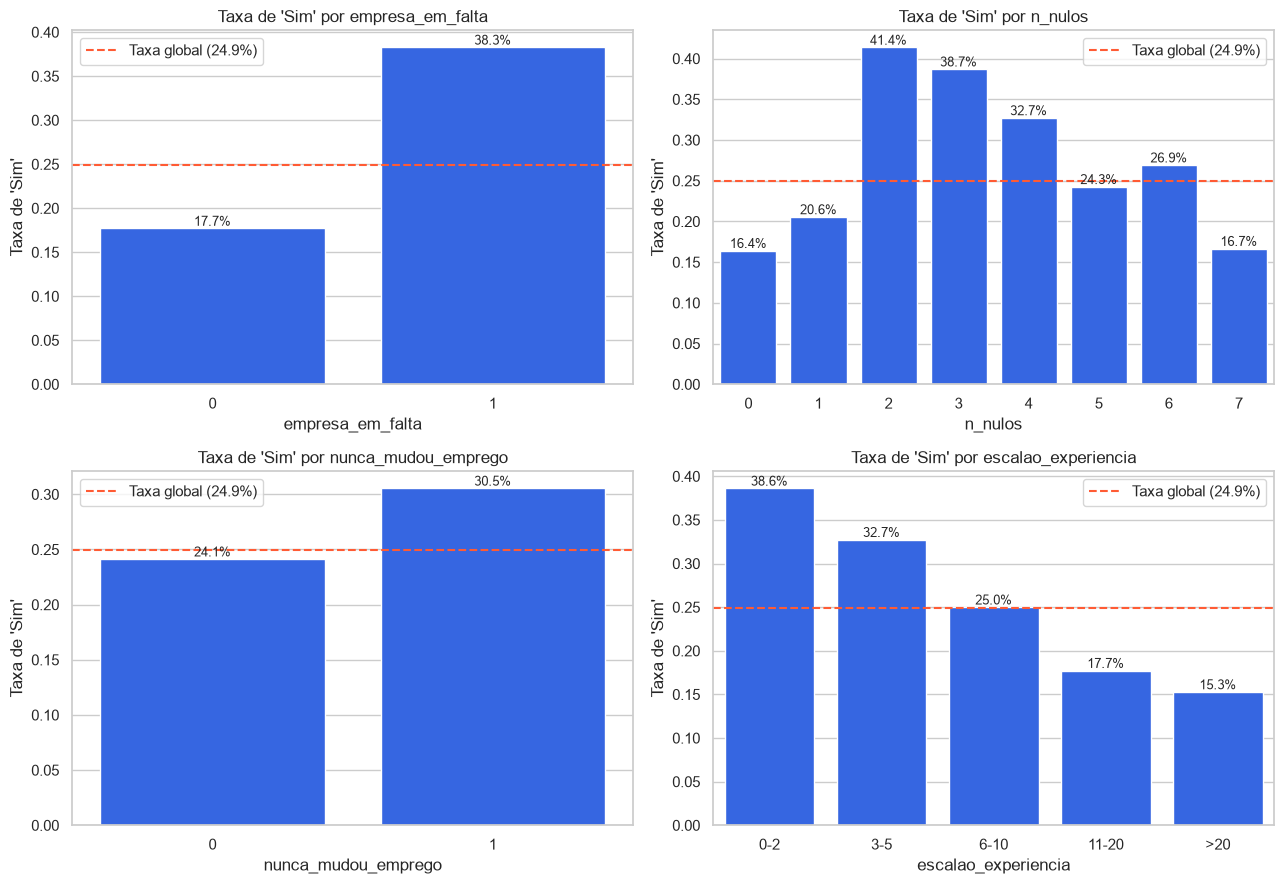

Figura guardada em: Data\analytics\04_horas_formacao_log_boxplot.png


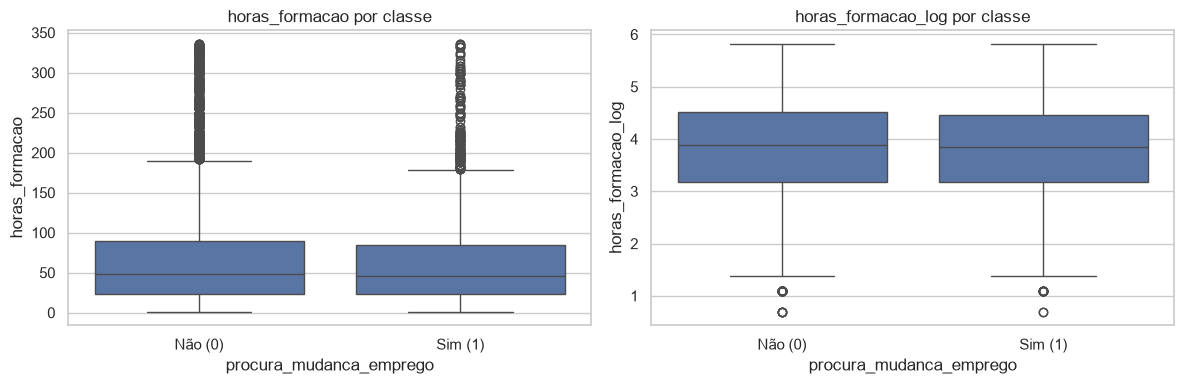

In [35]:
treino = X_train.join(y_train)   # só treino (o teste continua intocado)
taxa_global = y_train.mean()

# 1. Barplots da taxa de "Sim" (variáveis com poucos valores)
vars_barras = ["empresa_em_falta", "n_nulos", "nunca_mudou_emprego", "escalao_experiencia"]
ordens = {"escalao_experiencia": ["0-2", "3-5", "6-10", "11-20", ">20"]}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, vars_barras):
    sns.barplot(data=treino, x=col, y=TARGET, order=ordens.get(col),
                errorbar=None, color="#1A59FD", ax=ax)
    ax.axhline(taxa_global, color="#FF5B34", linestyle="--",
               label=f"Taxa global ({taxa_global:.1%})")
    ax.set_title(f"Taxa de 'Sim' por {col}")
    ax.set_ylabel("Taxa de 'Sim'")
    for p in ax.patches:                                  # valor em cima de cada barra
        ax.annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.legend()
plt.tight_layout()
guardar_figura("04_novas_variaveis_taxa")
plt.show()

# 2. Boxplots: horas_formacao original vs log, por classe
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["horas_formacao", "horas_formacao_log"]):
    sns.boxplot(data=treino, x=TARGET, y=col, ax=ax)
    ax.set_xticks([0, 1], ["Não (0)", "Sim (1)"])
    ax.set_title(f"{col} por classe")
plt.tight_layout()
guardar_figura("04_horas_formacao_log_boxplot")
plt.show()

##### Análise e Interpretação

> *As novas variáveis separam melhor as classes do que as originais?*

**Resposta:**

- `empresa_em_falta`: separa bem. No gráfico, a barra de quem não tem dados da empresa (1) fica claramente acima da taxa global (30,5 %), e a de quem tem dados (0) fica abaixo (24,1%). Resume em 2 valores o sinal que já se via nas categorias "Em falta" de `tipo_empresa` e `dimensao_empresa` (Fase 2, secção 5.2).
- `n_nulos`: separa bem. As barras sobem à medida que aumenta o número de valores em falta: quanto menos informação temos sobre o candidato, maior a taxa de "Sim".
- `escalao_experiencia`: separa bem e é mais clara do que a original. As barras descem de "0-2" (38,6%) para ">20" (15,3%). Mostra a mesma tendência de `anos_experiencia`, mas em 5 categorias em vez de 22, sem as oscilações das categorias pequenas.
- `nunca_mudou_emprego`: separa pouco. A barra de quem nunca mudou de emprego fica perto da taxa global (30,5 % vs 24,1 %).
- `horas_formacao_log`: não separa melhor. Nos boxplots, as caixas de "Não" e "Sim" continuam praticamente à mesma altura, tal como na variável original. O log torna a distribuição mais simétrica (menos outliers), o que é útil para modelos lineares, mas não cria separação entre classes.

- Conclusão: as variáveis ligadas aos dados em falta e o escalão de experiência separam as classes tão bem ou melhor (de forma mais simples e legível) do que as originais. A transformação logarítmica serve apenas para melhorar a forma da distribuição.

<hr>

**4.2 [Regressão] Avaliar as novas variáveis (no treino)**
- Correlação das novas variáveis numéricas com o target.

##### Análise e Interpretação

> *As novas variáveis têm relação mais forte com o alvo do que as originais?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Criar muitas colunas sem critério aumenta o ruído e o risco de <b>overfitting</b>. Nem todas as variáveis criadas melhoram o problema — mantenham apenas as que têm justificação.</div>

#### Definição das listas de variáveis

A partir daqui trabalha-se com listas explícitas de variáveis numéricas e categóricas (sem IDs nem target).

**4.3 Listas finais de variáveis**
- Criar `NUM_COLS` e `CAT_COLS` a partir de `X_train`, sem identificadores nem target.
- Ajustar manualmente, se necessário (ex.: numérica que é na verdade categórica).

In [ ]:
# 1. Confirmar que não há ID nem target em X_train
print("ID no índice:", X_train.index.name)
print("Target em X_train?", TARGET in X_train.columns)        
print("Nº de colunas:", X_train.shape[1])                    

# 2. Listas automáticas pelo tipo de dados
NUM_COLS = X_train.select_dtypes(include="number").columns.tolist()
CAT_COLS = X_train.select_dtypes(exclude="number").columns.tolist()

print("\nAutomático:")
print("NUM_COLS:", NUM_COLS)
print("CAT_COLS:", CAT_COLS)

ID no índice: id_candidato
Target em X_train? False
Nº de colunas: 16

Automático:
NUM_COLS: ['indice_desenvolvimento_cidade', 'anos_experiencia', 'anos_desde_ultimo_emprego', 'horas_formacao', 'empresa_em_falta', 'n_nulos', 'horas_formacao_log', 'nunca_mudou_emprego']
CAT_COLS: ['genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'dimensao_empresa', 'tipo_empresa', 'escalao_experiencia']


In [37]:
# 3. Binárias (0/1): são numéricas, mas não têm nulos nem precisam de scaling
BIN_COLS = ["empresa_em_falta", "nunca_mudou_emprego"]
NUM_COLS = [c for c in NUM_COLS if c not in BIN_COLS]

# 4. Categóricas com ordem natural -> OrdinalEncoder
ORD_COLS = ["nivel_educacao", "dimensao_empresa", "escalao_experiencia"]

# 5. Categóricas sem ordem -> OneHotEncoder
NOM_COLS = [c for c in CAT_COLS if c not in ORD_COLS]

print("NUM_COLS:", NUM_COLS)
print("BIN_COLS:", BIN_COLS)
print("CAT_COLS:", CAT_COLS)
print("   ORD_COLS:", ORD_COLS)
print("   NOM_COLS:", NOM_COLS)

# 6. Verificação: todas as colunas estão numa (e só numa) lista
todas = NUM_COLS + BIN_COLS + CAT_COLS
print("\nTodas as colunas cobertas?", sorted(todas) == sorted(X_train.columns))
print("Sem repetições?", len(todas) == len(set(todas)))

NUM_COLS: ['indice_desenvolvimento_cidade', 'anos_experiencia', 'anos_desde_ultimo_emprego', 'horas_formacao', 'n_nulos', 'horas_formacao_log']
BIN_COLS: ['empresa_em_falta', 'nunca_mudou_emprego']
CAT_COLS: ['genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'dimensao_empresa', 'tipo_empresa', 'escalao_experiencia']
   ORD_COLS: ['nivel_educacao', 'dimensao_empresa', 'escalao_experiencia']
   NOM_COLS: ['genero', 'experiencia_relevante', 'inscricao_universidade', 'area_formacao', 'tipo_empresa']

Todas as colunas cobertas? True
Sem repetições? True


- As listas foram criadas automaticamente a partir dos tipos de `X_train` (sem `id_candidato`, que está no índice, nem o target): 8 numéricas e 8 categóricas, num total de 16 variáveis (11 originais + 5 criadas na secção 4.1).
- Ajustes manuais:
  - `empresa_em_falta` e `nunca_mudou_emprego` foram retiradas de `NUM_COLS` para uma lista própria (`BIN_COLS`): são indicadores 0/1 sem nulos, que não precisam de imputação nem de escalonamento.
  - As categóricas foram divididas em ordinais (`nivel_educacao`, `dimensao_empresa`, `escalao_experiencia`), que têm uma ordem natural e serão codificadas com `OrdinalEncoder`, e nominais (`genero`, `experiencia_relevante`, `inscricao_universidade`, `area_formacao`, `tipo_empresa`), sem ordem, que serão codificadas com one-hot.
  - `anos_experiencia` e `anos_desde_ultimo_emprego` já são numéricas desde a conversão da secção 2.3.
- Foi verificado que cada variável pertence a uma só lista e que todas as colunas de `X_train` estão incluídas.
- Mantêm-se, por agora, pares redundantes (`anos_experiencia`/`escalao_experiencia`, `horas_formacao`/`horas_formacao_log`); a escolha será feita na seleção de variáveis.

### 5. Valores em falta
<hr>

**Estratégias possíveis**

| Estratégia (M3.02) | Quando | Nota |
|---|---|---|
| Remover **linhas** (`dropna`) | poucos nulos, MCAR | perde dados |
| Remover **colunas** | coluna quase toda nula (ex.: `deck`) | perde a variável |
| Imputar **média** | numérica simétrica | sensível a outliers |
| Imputar **mediana** | numérica assimétrica | robusta |
| Imputar **moda** | categórica | — |
| Imputar **constante** | "Desconhecido" / 0 | preserva o "não sabido" |
| Imputar **por grupo** | há grupos informativos (ex.: mediana da idade por classe) | melhor estimativa |
| **KNNImputer** | relações entre variáveis | mais custoso |
| **IterativeImputer (MICE)** | missing complexo | modela cada coluna |
| **Indicador de missing** (`add_indicator=True`) | o facto de faltar é informativo | cria uma flag |

Os valores usados na imputação são calculados **no treino** (o imputer dentro do Pipeline garante isto).

**5.1 Valores em falta no treino**
- Tabela com nº e % de nulos por coluna em `X_train` (só as colunas com nulos).

In [38]:
#levantamento dos nulos só no treino (já sabemos os nºs da fase2 e agora temos uma nova coluna c/ nulos - escalao_experiencia)

# Nº e % de nulos por coluna (só colunas com nulos), ordenado do maior para o menor
nulos = pd.DataFrame({
    "n_nulos": X_train.isna().sum(),
    "pct_nulos": (X_train.isna().mean() * 100).round(2),
})
nulos = nulos[nulos["n_nulos"] > 0].sort_values("pct_nulos", ascending=False)

# Juntar a lista a que cada coluna pertence (para planear o tratamento)
def tipo_coluna(c):
    if c in NUM_COLS: return "numérica"
    if c in ORD_COLS: return "ordinal"
    if c in NOM_COLS: return "nominal"
    if c in BIN_COLS: return "binária"
nulos["tipo"] = [tipo_coluna(c) for c in nulos.index]

print(f"Linhas no treino: {len(X_train)}")
print(f"Linhas com pelo menos 1 nulo: {X_train.isna().any(axis=1).mean() * 100:.1f}%\n")
nulos

Linhas no treino: 15326
Linhas com pelo menos 1 nulo: 53.3%



,n_nulos,pct_nulos,tipo
tipo_empresa,4921,32.11,nominal
dimensao_empresa,4773,31.14,ordinal
genero,3584,23.39,nominal
area_formacao,2234,14.58,nominal
nivel_educacao,357,2.33,ordinal
anos_desde_ultimo_emprego,337,2.20,numérica
inscricao_universidade,305,1.99,nominal
anos_experiencia,50,0.33,numérica
escalao_experiencia,50,0.33,ordinal


##### Análise e Interpretação

> *Que variáveis precisam de tratamento? Com que peso?*

**Resposta:**

- 9 variáveis precisam de tratamento em `X_train` (15 326 linhas); cerca de 53,3 % das linhas têm pelo menos um nulo, pelo que remover linhas (`dropna`) não é opção.
- Peso elevado (> 20%): `tipo_empresa` (32,11 %), `dimensao_empresa` (31,14 %) e `genero` (23,39 %). São demasiados para imputar com a moda sem distorcer a distribuição, mas não justificam remover as colunas: na Fase 2 viu-se que a falta de dados da empresa está associada ao alvo (38,0% de "Sim" vs 17,9%). → Imputar com uma categoria própria* ("Em falta"), preservando essa informação (já capturada também em `empresa_em_falta` e `n_nulos`). 
- Peso moderado: `area_formacao` (14,58 %). Os nulos são estruturais: correspondem a candidatos sem ensino superior (Fase 2, secção 3.3) -> Categoria "Não aplicável".
- Peso baixo (< 3%): `nivel_educacao` (2,33 %), `anos_desde_ultimo_emprego` (2,20 %), `inscricao_universidade` (1,99 %), `anos_experiencia` (0,3 %) e `escalao_experiencia` (0,3 %, herdados de `anos_experiencia`) -> Categóricas com "Em falta"; numéricas com a mediana do treino (distribuições assimétricas).
- As variáveis criadas na secção 4.1 (`empresa_em_falta`, `n_nulos`, `nunca_mudou_emprego`, `horas_formacao_log`), bem como `indice_desenvolvimento_cidade` e `horas_formacao`, não têm nulos.
- Todos os valores de imputação (ex.: medianas) serão calculados apenas no treino, através do imputer dentro do pipeline, e aplicados depois ao teste.

<hr>

**5.2 Comparar estratégias de imputação (M3.02)**
- Na variável numérica com mais nulos: comparar a distribuição original com a imputação pela média, pela mediana e com `KNNImputer` (tabela `describe` + `kdeplot`).
- (Opcional) Imputação por grupo com `groupby(...).transform("median")`: calcular as medianas por grupo em `X_train` e aplicá-las ao `X_test` com `map` — não usar `transform` no dataset completo nem no teste.

Nulos em anos_desde_ultimo_emprego (treino): 337 (2.2%)
Média do treino: 2.01 | Mediana do treino: 1
       Original (sem nulos)      Média    Mediana        KNN
count             14989.000  15326.000  15326.000  15326.000
mean                  2.009      2.009      1.986      2.004
std                   1.677      1.658      1.665      1.662
min                   0.000      0.000      0.000      0.000
25%                   1.000      1.000      1.000      1.000
50%                   1.000      1.000      1.000      1.000
75%                   3.000      3.000      3.000      3.000
max                   5.000      5.000      5.000      5.000

Proporção de cada valor (%):
                           Original  Mediana
anos_desde_ultimo_emprego                   
0.0                            12.9     12.6
1.0                            42.9     44.1
2.0                            15.5     15.2
3.0                             5.6      5.4
4.0                             5.5      5.3
5.0  

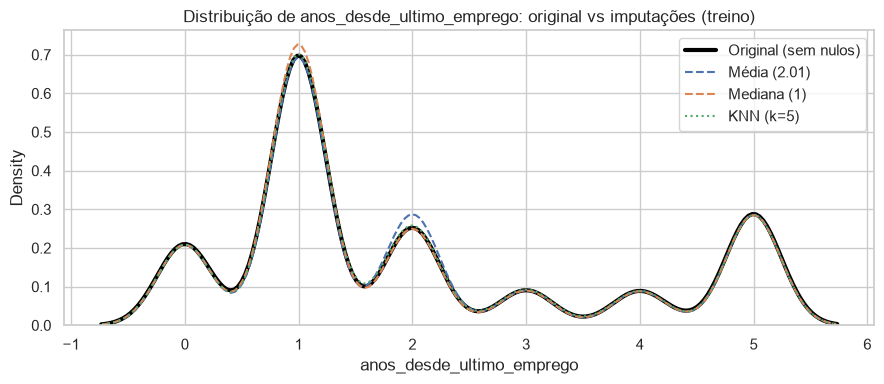

In [39]:
COL = "anos_desde_ultimo_emprego"
print(f"Nulos em {COL} (treino): {X_train[COL].isna().sum()} ({X_train[COL].isna().mean():.1%})")

# --- 1. Média e mediana (aprendidas no treino) ---
media   = X_train[COL].mean()
mediana = X_train[COL].median()
print(f"Média do treino: {media:.2f} | Mediana do treino: {mediana:.0f}")

imp_media   = X_train[COL].fillna(media)
imp_mediana = X_train[COL].fillna(mediana)

# --- 2. KNNImputer: usa as outras numéricas para encontrar os 5 candidatos mais parecidos ---
#     O KNN mede distâncias, por isso as variáveis têm de estar na mesma escala.
cols_knn = NUM_COLS + BIN_COLS
scaler_knn = StandardScaler().fit(X_train[cols_knn])                 # aprende no treino
dados_esc  = scaler_knn.transform(X_train[cols_knn])

knn = KNNImputer(n_neighbors=5).fit(dados_esc)                       # aprende no treino
dados_imp  = scaler_knn.inverse_transform(knn.transform(dados_esc))  # volta à escala original
imp_knn = pd.Series(dados_imp[:, cols_knn.index(COL)], index=X_train.index)

# --- 3. Tabela describe lado a lado ---
comparacao = pd.DataFrame({
    "Original (sem nulos)": X_train[COL].dropna(),
    "Média":   imp_media,
    "Mediana": imp_mediana,
    "KNN":     imp_knn,
}).describe().round(3)
print(comparacao)

# --- 4. Proporção de cada valor (útil porque a variável só tem 0 a 5) ---
props = pd.DataFrame({
    "Original": X_train[COL].value_counts(normalize=True),
    "Mediana":  imp_mediana.value_counts(normalize=True),
}).sort_index().mul(100).round(1)
print("\nProporção de cada valor (%):")
print(props)

# --- 5. kdeplot ---
plt.figure(figsize=(9, 4))
sns.kdeplot(X_train[COL].dropna(), label="Original (sem nulos)", linewidth=3, color="black")
sns.kdeplot(imp_media,   label=f"Média ({media:.2f})", linestyle="--")
sns.kdeplot(imp_mediana, label=f"Mediana ({mediana:.0f})", linestyle="--")
sns.kdeplot(imp_knn,     label="KNN (k=5)", linestyle=":")
plt.title(f"Distribuição de {COL}: original vs imputações (treino)")
plt.legend()
plt.tight_layout()
guardar_figura("05_comparacao_imputacao")
plt.show()

In [40]:
# Medianas por grupo, calculadas SÓ no treino
medianas_grupo = X_train.groupby("escalao_experiencia")[COL].median()
print(medianas_grupo)

def imputar_por_grupo(data):
    valores_grupo = data["escalao_experiencia"].map(medianas_grupo)   # mediana do grupo de cada linha
    return data[COL].fillna(valores_grupo).fillna(mediana)            # se o grupo for nulo -> mediana global

imp_grupo_treino = imputar_por_grupo(X_train)
imp_grupo_teste  = imputar_por_grupo(X_test)   # usa as medianas do TREINO
print("Nulos restantes (treino/teste):", imp_grupo_treino.isna().sum(), imp_grupo_teste.isna().sum())

escalao_experiencia
0-2      1.0
11-20    2.0
3-5      1.0
6-10     1.0
>20      4.0
Name: anos_desde_ultimo_emprego, dtype: float64
Nulos restantes (treino/teste): 0 0


##### Análise e Interpretação

> *Que estratégia deforma menos a distribuição? Qual escolhem e porquê?*

**Resposta:**

- 

<hr>

**5.3 Estratégias escolhidas**
- Guardar em variáveis as decisões que vão para o Pipeline: `ESTRATEGIA_NUM` (`"mean"`, `"median"` ou `"knn"`), `ESTRATEGIA_CAT` (`"most_frequent"` ou `"constant"`) e `ADD_INDICATOR` (True/False).

In [41]:
# Decisões de imputação (vão para o Pipeline)
ESTRATEGIA_NUM = "median"     # numéricas assimétricas, poucos nulos (secção 5.2)
ESTRATEGIA_CAT = "constant"   # nulos das categóricas como categoria própria
FILL_VALUE_CAT = "Em falta"   # valor usado pela estratégia "constant"
ADD_INDICATOR  = False        # não: a informação de "em falta" já está nas features criadas

print("ESTRATEGIA_NUM:", ESTRATEGIA_NUM)
print("ESTRATEGIA_CAT:", ESTRATEGIA_CAT, f"(fill_value='{FILL_VALUE_CAT}')")
print("ADD_INDICATOR: ", ADD_INDICATOR)

# Teste rápido: os imputers funcionam no treino e não deixam nulos?
imp_num = SimpleImputer(strategy=ESTRATEGIA_NUM, add_indicator=ADD_INDICATOR)
imp_cat = SimpleImputer(strategy=ESTRATEGIA_CAT, fill_value=FILL_VALUE_CAT,
                        add_indicator=ADD_INDICATOR)

teste_num = imp_num.fit_transform(X_train[NUM_COLS])
teste_cat = imp_cat.fit_transform(X_train[CAT_COLS])

print("\nNulos após imputação - numéricas:", pd.DataFrame(teste_num).isna().sum().sum())   # 0
print("Nulos após imputação - categóricas:", pd.DataFrame(teste_cat).isna().sum().sum())   # 0
print("Medianas aprendidas no treino:", dict(zip(NUM_COLS, imp_num.statistics_.round(2))))

ESTRATEGIA_NUM: median
ESTRATEGIA_CAT: constant (fill_value='Em falta')
ADD_INDICATOR:  False

Nulos após imputação - numéricas: 0
Nulos após imputação - categóricas: 0
Medianas aprendidas no treino: {'indice_desenvolvimento_cidade': np.float64(0.91), 'anos_experiencia': np.float64(9.0), 'anos_desde_ultimo_emprego': np.float64(1.0), 'horas_formacao': np.float64(47.0), 'n_nulos': np.float64(1.0), 'horas_formacao_log': np.float64(3.87)}


### 6. Outliers
<hr>

- Foram identificados (IQR 1,5×, Z-score ±3, percentis 1%–99%)? Em que variáveis?
- São **erros** (corrigir/remover) ou **valores raros mas reais** (manter)?
- Que decisão foi tomada e qual o critério?

| Opção | Descrição |
|---|---|
| Manter | valores reais e informativos; usar modelos robustos (árvores) ou `RobustScaler` |
| Remover | apenas erros evidentes e **apenas no treino** |
| Limitar (*capping*) | `clip` aos limites IQR calculados no treino |
| *Winsorizing* | `clip` aos percentis 1% e 99% calculados no treino |
| Transformar | `np.log1p` para reduzir o efeito de valores extremos |

**Decisão (M3.02):** erro de medição → remover/corrigir; informação rara real → manter (capping/log preserva a observação sem a deixar dominar). Em variáveis assimétricas preferir **log** ou **RobustScaler** a remover.

**Nunca remover linhas do conjunto de teste:** o teste tem de representar os dados reais que o modelo vai encontrar.

**6.1 Deteção de outliers no treino**
- Para cada numérica: nº de outliers por IQR, Z-score e percentis (P1–P99), guardando os limites IQR calculados no treino.

In [42]:
resultados = []
LIMITES_IQR = {}   # limites calculados no TREINO (para usar depois, se houver capping)

for col in NUM_COLS:
    s = X_train[col].dropna()

    # 1. IQR (1,5x)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    LIMITES_IQR[col] = (lim_inf, lim_sup)
    n_iqr = ((s < lim_inf) | (s > lim_sup)).sum()

    # 2. Z-score (|z| > 3)
    z = (s - s.mean()) / s.std()
    n_z = (z.abs() > 3).sum()

    # 3. Percentis (fora de P1–P99)
    p1, p99 = s.quantile([0.01, 0.99])
    n_pct = ((s < p1) | (s > p99)).sum()

    resultados.append({
        "variável": col,
        "min": s.min(), "max": s.max(),
        "lim_inf_IQR": round(lim_inf, 3), "lim_sup_IQR": round(lim_sup, 3),
        "n_IQR": n_iqr, "%_IQR": round(n_iqr / len(s) * 100, 2),
        "n_Zscore": n_z, "n_P1_P99": n_pct,
    })

outliers = pd.DataFrame(resultados).set_index("variável")
outliers



,min,max,lim_inf_IQR,lim_sup_IQR,n_IQR,%_IQR,n_Zscore,n_P1_P99
variável,,,,,,,,
indice_desenvolvimento_cidade,0.448000,0.949000,0.470,1.190,13,0.08,13,207
anos_experiencia,0.000000,21.000000,-14.000,34.000,0,0.00,0,0
anos_desde_ultimo_emprego,0.000000,5.000000,-2.000,6.000,0,0.00,0,0
horas_formacao,1.000000,336.000000,-74.500,185.500,791,5.16,352,232
n_nulos,0.000000,7.000000,-3.000,5.000,58,0.38,194,58
horas_formacao_log,0.693147,5.820083,1.212,6.455,84,0.55,7,232


Figura guardada em: Data\analytics\06_outliers_boxplots_treino.png


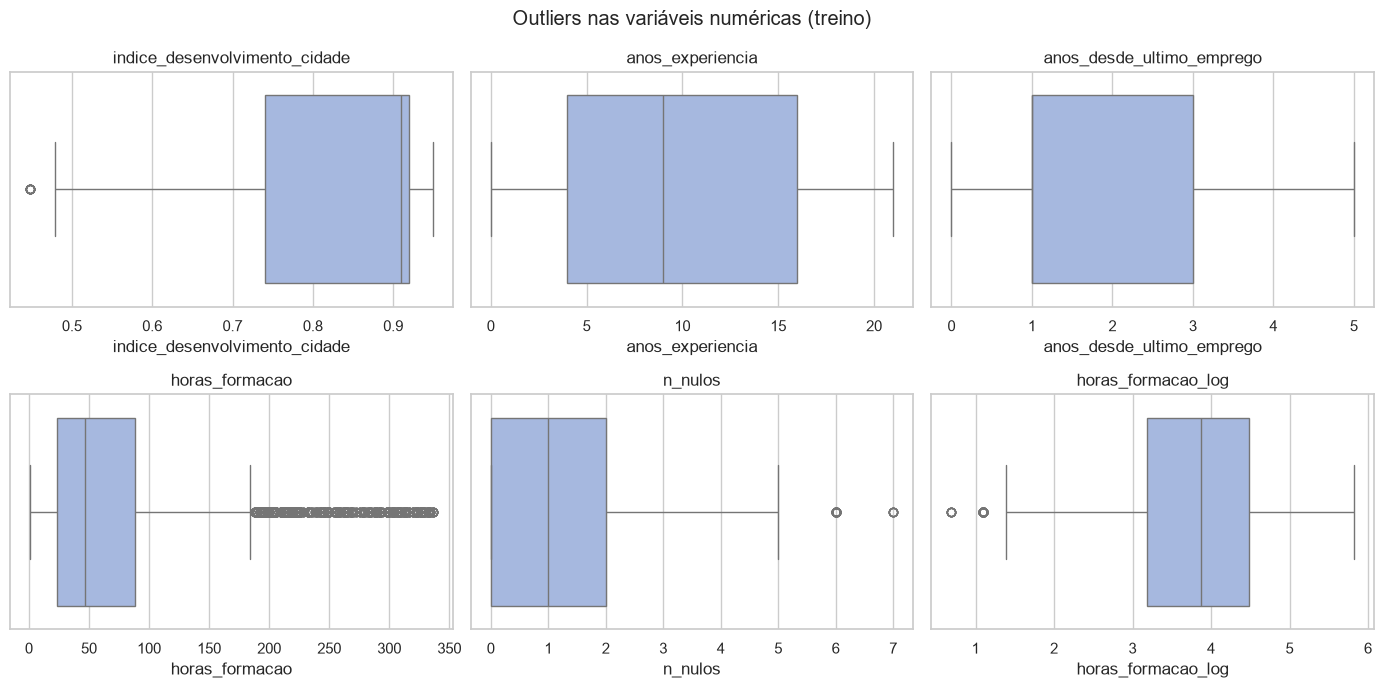

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, NUM_COLS):
    sns.boxplot(x=X_train[col], ax=ax, color="#9DB4E8")
    ax.set_title(col)
plt.suptitle("Outliers nas variáveis numéricas (treino)")
plt.tight_layout()
guardar_figura("06_outliers_boxplots_treino")
plt.show()

##### Análise e Interpretação

> *Que variáveis têm outliers? São erros ou valores reais?*

**Resposta:**



<hr>

**6.2 Tratamento de outliers (se aplicável)**
- Aplicar a decisão tomada: capping (`clip` aos limites IQR), winsorizing (`clip` a P1–P99) ou `np.log1p`.
- Os limites são calculados **no treino** e aplicados **da mesma forma** ao teste.

In [ ]:
# manter os outliers - os valores são reais e possíveis e com infrmações relevantes

##### Análise e Interpretação

> *Que tratamento foi aplicado e com que critério? Porque não remover as linhas?*

**Resposta:**

- 

<hr>

### 7. Encoding de variáveis categóricas
<hr>

| Estratégia (M3.01) | Quando usar | Cuidado |
|---|---|---|
| **Label / Ordinal** | binárias ou ordinais (com ordem real); `LabelEncoder` no **alvo** | introduz ordem artificial em nominais |
| **One-Hot** | nominais com poucas categorias | aumenta a dimensionalidade; `handle_unknown="ignore"` evita erros com categorias novas |
| **Frequency** | nominais com muitas categorias | categorias com igual frequência colidem |
| **Target / Mean** | muitas categorias, com relação ao alvo | **data leakage** → ajustar **só no treino** |
| **Binary / Hashing** (avançado) | cardinalidade muito alta | menos interpretável |

`pd.get_dummies(drop_first=True)` serve para análises rápidas, mas não guarda as categorias do treino → num projeto preferir o `OneHotEncoder` dentro do Pipeline.

**7.1 Categorias por variável (treino)**
- Para cada categórica: nº de categorias e lista das categorias.

In [44]:
for col in CAT_COLS:
    cats = X_train[col].fillna(FILL_VALUE_CAT).value_counts()
    print(f"--- {col} ({len(cats)} categorias) ---")
    print(cats.to_string(), "\n")

--- genero (4 categorias) ---
genero
Masculino    10598
Em falta      3584
Feminino       986
Outro          158 

--- experiencia_relevante (2 categorias) ---
experiencia_relevante
Com experiência relevante    11046
Sem experiência relevante     4280 

--- inscricao_universidade (4 categorias) ---
inscricao_universidade
Não inscrito             11047
Curso a tempo inteiro     3005
Curso a tempo parcial      969
Em falta                   305 

--- nivel_educacao (6 categorias) ---
nivel_educacao
Licenciatura         9294
Mestrado             3473
Ensino Secundário    1620
Em falta              357
Doutoramento          343
Ensino Básico         239 

--- area_formacao (7 categorias) ---
area_formacao
Ciência, Tecnologia, Engenharia e Matemática    11610
Em falta                                         2234
Humanidades                                       533
Outro                                             312
Gestão e Negócios                                 258
Artes              

In [45]:
ORD_COLS = ["nivel_educacao", "escalao_experiencia"]
NOM_COLS = [c for c in CAT_COLS if c not in ORD_COLS]   # agora inclui dimensao_empresa

# Ordem das ordinais (ajusta os textos ao output acima!)
# "Em falta" fica na posição mais baixa (0): é uma escolha nossa, justificada abaixo
ORDENS = {
    "nivel_educacao":      ["Em falta", "Ensino Básico", "Ensino Secundário",
                            "Licenciatura", "Mestrado", "Doutoramento"],
    "escalao_experiencia": ["Em falta", "0-2", "3-5", "6-10", "11-20", ">20"],
}

# Verificação: todas as categorias do treino estão na ordem definida?
for col, ordem in ORDENS.items():
    em_falta_na_ordem = set(X_train[col].fillna(FILL_VALUE_CAT).unique()) - set(ordem)
    print(col, "-> categorias não previstas:", em_falta_na_ordem or "nenhuma")

print("\nORD_COLS:", ORD_COLS)
print("NOM_COLS:", NOM_COLS)

nivel_educacao -> categorias não previstas: nenhuma
escalao_experiencia -> categorias não previstas: nenhuma

ORD_COLS: ['nivel_educacao', 'escalao_experiencia']
NOM_COLS: ['genero', 'experiencia_relevante', 'inscricao_universidade', 'area_formacao', 'dimensao_empresa', 'tipo_empresa']


In [46]:
n_colunas_ohe = sum(X_train[c].fillna(FILL_VALUE_CAT).nunique() for c in NOM_COLS)
print("Colunas criadas pelo one-hot:", n_colunas_ohe)

Colunas criadas pelo one-hot: 33


##### Análise e Interpretação

> *Que encoding é adequado a cada variável (nominal, ordinal, binária, alta cardinalidade)?*

**Resposta:**

| Variável | Tipo | Encoding | Justificação |
|---|---|---|---|
| `procura_mudanca_emprego` (alvo) | binária | `map` {"Não": 0, "Sim": 1} | Feito na secção 2.5; classe de interesse = 1 |
| `experiencia_relevante` | binária (sem nulos) | One-hot com `drop="if_binary"` (fica uma única coluna 0/1) | Só 2 categorias; uma coluna chega |
| `genero` | nominal | One-hot | Sem ordem; 4 categorias (com "Em falta") |
| `inscricao_universidade` | nominal | One-hot | Tipos de inscrição sem ordem clara |
| `area_formacao` | nominal | One-hot | Sem ordem; "Em falta" = não aplicável (sem ensino superior) |
| `tipo_empresa` | nominal | One-hot | Sem ordem; "Em falta" é informativo (H6) |
| `dimensao_empresa` | ordinal com ~31% "Em falta" | One-hot | Ver nota abaixo |
| `nivel_educacao` | ordinal | `OrdinalEncoder` (Em falta < Básico < Secundário < Licenciatura < Mestrado < Doutoramento) | Ordem real de escolaridade |
| `escalao_experiencia` | ordinal | `OrdinalEncoder` (Em falta < 0-2 < 3-5 < 6-10 < 11-20 < >20) | Escalões criados por nós, com ordem |
| `empresa_em_falta`, `nunca_mudou_emprego` | binárias 0/1 | Nenhum (já numéricas) | Criadas na secção 4.1 |

- **Nominais → one-hot**, porque um encoding numérico (1, 2, 3...) criaria uma ordem artificial (ex.: "Masculino" < "Feminino"). Todas têm poucas categorias (≤ 9), pelo que o aumento de dimensionalidade é aceitável (33 colunas no total). Usa-se `handle_unknown="ignore"` para evitar erros se o teste tiver uma categoria que não apareceu no treino.
- **Ordinais → `OrdinalEncoder` com ordem definida manualmente** (não alfabética), para o modelo usar a ordem natural. A categoria "Em falta" ficou na posição mais baixa: em `nivel_educacao` é coerente com a Fase 2 (nos candidatos sem nível indicado, a área de formação também está sempre em falta, tal como nos níveis sem ensino superior), e em `escalao_experiencia` afeta apenas ~0,3% dos candidatos.
- **`dimensao_empresa` passou de ordinal para one-hot:** depois da imputação, ~31% dos candidatos ficam em "Em falta", que não tem posição natural na escala de dimensão e tem a taxa de "Sim" mais alta. Forçá-la numa posição distorceria a ordem; com one-hot, cada categoria (incluindo "Em falta") tem a sua própria coluna.
- **Alta cardinalidade:** não há. A única variável com muitas categorias era `cidade` (123), removida na secção 1. Por isso não é necessário frequency ou target encoding (o que também evita o risco de data leakage do target encoding).
- Os encoders são ajustados **apenas no treino** (aprendem as categorias) dentro do pipeline; não se usa `pd.get_dummies`, que não guarda as categorias do treino.

<hr>

**7.2 One-Hot Encoding**
- `OneHotEncoder(handle_unknown="ignore")` ajustado no treino; mostrar as colunas geradas (`get_feature_names_out`).

In [47]:
# 1. Preparar cópias com os nulos como "Em falta" (como fará o imputer do pipeline)
X_train_nom = X_train[NOM_COLS].fillna(FILL_VALUE_CAT)
X_test_nom  = X_test[NOM_COLS].fillna(FILL_VALUE_CAT)

# 2. OneHotEncoder: aprende as categorias SÓ no treino
ohe = OneHotEncoder(
    handle_unknown="ignore",   # categoria nova no teste -> tudo 0, sem erro
    drop="if_binary",          # variáveis com 2 categorias ficam numa só coluna
    sparse_output=False        # devolve uma tabela normal (mais fácil de ver)
)
ohe.fit(X_train_nom)

# 3. Transformar treino e teste com as categorias aprendidas no treino
colunas_ohe = ohe.get_feature_names_out(NOM_COLS)
X_train_ohe = pd.DataFrame(ohe.transform(X_train_nom), columns=colunas_ohe, index=X_train.index)
X_test_ohe  = pd.DataFrame(ohe.transform(X_test_nom),  columns=colunas_ohe, index=X_test.index)

# 4. Resumo: quantas colunas por variável
print(f"Variáveis nominais: {len(NOM_COLS)} -> colunas one-hot: {len(colunas_ohe)}\n")
for col, cats in zip(NOM_COLS, ohe.categories_):
    n_cols = sum(c.startswith(col + "_") for c in colunas_ohe)
    print(f"{col}: {len(cats)} categorias -> {n_cols} coluna(s)")

print("\nTreino:", X_train_ohe.shape, "| Teste:", X_test_ohe.shape)   # mesmo nº de colunas
print("\nColunas geradas:")
print(list(colunas_ohe))
X_train_ohe.head()

Variáveis nominais: 6 -> colunas one-hot: 32

genero: 4 categorias -> 4 coluna(s)
experiencia_relevante: 2 categorias -> 1 coluna(s)
inscricao_universidade: 4 categorias -> 4 coluna(s)
area_formacao: 7 categorias -> 7 coluna(s)
dimensao_empresa: 9 categorias -> 9 coluna(s)
tipo_empresa: 7 categorias -> 7 coluna(s)

Treino: (15326, 32) | Teste: (3832, 32)

Colunas geradas:
['genero_Em falta', 'genero_Feminino', 'genero_Masculino', 'genero_Outro', 'experiencia_relevante_Sem experiência relevante', 'inscricao_universidade_Curso a tempo inteiro', 'inscricao_universidade_Curso a tempo parcial', 'inscricao_universidade_Em falta', 'inscricao_universidade_Não inscrito', 'area_formacao_Artes', 'area_formacao_Ciência, Tecnologia, Engenharia e Matemática', 'area_formacao_Em falta', 'area_formacao_Gestão e Negócios', 'area_formacao_Humanidades', 'area_formacao_Outro', 'area_formacao_Sem especialização', 'dimensao_empresa_10 a 49', 'dimensao_empresa_100 a 500', 'dimensao_empresa_1000 a 4999', 'dime

,genero_Em falta,genero_Feminino,genero_Masculino,genero_Outro,experiencia_relevante_Sem experiência relevante,inscricao_universidade_Curso a tempo inteiro,inscricao_universidade_Curso a tempo parcial,inscricao_universidade_Em falta,inscricao_universidade_Não inscrito,area_formacao_Artes,"area_formacao_Ciência, Tecnologia, Engenharia e Matemática",area_formacao_Em falta,area_formacao_Gestão e Negócios,area_formacao_Humanidades,area_formacao_Outro,area_formacao_Sem especialização,dimensao_empresa_10 a 49,dimensao_empresa_100 a 500,dimensao_empresa_1000 a 4999,dimensao_empresa_10000 ou mais,dimensao_empresa_50 a 99,dimensao_empresa_500 a 999,dimensao_empresa_5000 a 9999,dimensao_empresa_Em falta,dimensao_empresa_Menos de 10,tipo_empresa_Em falta,tipo_empresa_Empresa privada,tipo_empresa_ONG,tipo_empresa_Outro,tipo_empresa_Setor público,tipo_empresa_Startup em fase inicial,tipo_empresa_Startup financiada
id_candidato,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
966838,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
675381,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
927526,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
239005,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
392878,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


##### Análise e Interpretação

> *Quantas colunas foram criadas? Porque é útil o `handle_unknown="ignore"`?*

**Resposta:**

- **Colunas criadas:** as 6 variáveis nominais deram origem a **32 colunas** one-hot (uma por categoria, incluindo "Em falta"):
  - `genero`: 4 colunas; `inscricao_universidade`: 4; `area_formacao`: 7; `tipo_empresa`: 7; `dimensao_empresa`: 9;
  - `experiencia_relevante`: **1 coluna**, porque tem só 2 categorias e com `drop="if_binary"` a segunda coluna seria redundante (é sempre o inverso da primeira).
- O encoder foi ajustado **apenas no treino** (aprendeu as categorias) e aplicado ao treino e ao teste, que ficaram com **o mesmo número e a mesma ordem de colunas**.
- **Porque é útil `handle_unknown="ignore"`:** se no teste (ou em dados futuros) aparecer uma categoria que não existia no treino, o encoder não dá erro: põe 0 em todas as colunas dessa variável. Sem esta opção, o pipeline falharia com dados novos. Neste dataset, todas as categorias do teste existem no treino (as categorias são poucas e frequentes), mas a opção torna o pipeline robusto para uso real. Foi testado com uma categoria inventada ("Cooperativa"): todas as colunas de `tipo_empresa` ficaram a 0, sem erro.
- O aumento de dimensionalidade (de 6 para 32 colunas) é aceitável, porque todas as variáveis têm poucas categorias.

<hr>

**7.3 Outras estratégias de encoding (M3.01)**
- Binária: `(X["col"] == "valor").astype(int)`.
- Frequency encoding: `map(value_counts(normalize=True))` calculado no treino.
- Target encoding: `y_train.groupby(X_train[col]).mean()` — **só no treino**, depois aplicado ao teste.

In [48]:
# --- 1. Encoding binário: experiencia_relevante (2 categorias, sem nulos) ---
print("Categorias:", X_train["experiencia_relevante"].unique())
VALOR_POSITIVO = X_train["experiencia_relevante"].unique()[0]   # ajusta ao texto de "tem experiência"

bin_train = (X_train["experiencia_relevante"] == VALOR_POSITIVO).astype(int)
bin_test  = (X_test["experiencia_relevante"]  == VALOR_POSITIVO).astype(int)
print(f"\n1 = '{VALOR_POSITIVO}'")
print(pd.crosstab(X_train["experiencia_relevante"], bin_train))


# --- 2. Frequency encoding: tipo_empresa (frequências calculadas no TREINO) ---
COL = "tipo_empresa"
tr = X_train[COL].fillna(FILL_VALUE_CAT)
te = X_test[COL].fillna(FILL_VALUE_CAT)

freq = tr.value_counts(normalize=True)          # aprende no treino
freq_train = tr.map(freq)
freq_test  = te.map(freq).fillna(0)             # categoria nova no teste -> frequência 0

print(f"\nFrequency encoding de {COL} (treino):")
print(freq.round(3))


# --- 3. Target encoding: tipo_empresa (taxa de "Sim" por categoria, só no TREINO) ---
taxa = y_train.groupby(tr).mean()               # aprende no treino (usa o alvo!)
te_train = tr.map(taxa)
te_test  = te.map(taxa).fillna(y_train.mean())  # categoria nova -> taxa global do treino

print(f"\nTarget encoding de {COL} (taxa de 'Sim' no treino):")
print(pd.DataFrame({"taxa_sim": taxa.round(3), "n": tr.value_counts()}).sort_values("taxa_sim"))


# --- 4. Comparação lado a lado (primeiras linhas do treino) ---
pd.DataFrame({
    COL: tr, "frequency": freq_train.round(3), "target_enc": te_train.round(3)
}).head(8)

Categorias: <StringArray>
['Com experiência relevante', 'Sem experiência relevante']
Length: 2, dtype: str

1 = 'Com experiência relevante'
experiencia_relevante         0      1
experiencia_relevante                 
Com experiência relevante     0  11046
Sem experiência relevante  4280      0

Frequency encoding de tipo_empresa (treino):
tipo_empresa
Empresa privada            0.512
Em falta                   0.321
Startup financiada         0.052
Setor público              0.051
Startup em fase inicial    0.032
ONG                        0.026
Outro                      0.006
Name: proportion, dtype: float64

Target encoding de tipo_empresa (taxa de 'Sim' no treino):
                         taxa_sim     n
tipo_empresa                           
Startup financiada          0.140   794
Empresa privada             0.177  7844
ONG                         0.187   401
Setor público               0.233   782
Startup em fase inicial     0.238   491
Outro                       0.258    93
E

,tipo_empresa,frequency,target_enc
id_candidato,,,
966838,Empresa privada,0.512,0.177
675381,Empresa privada,0.512,0.177
927526,Empresa privada,0.512,0.177
239005,Empresa privada,0.512,0.177
392878,Startup em fase inicial,0.032,0.238
779074,Empresa privada,0.512,0.177
588779,Empresa privada,0.512,0.177
636317,Empresa privada,0.512,0.177


##### Análise e Interpretação

> *Que estratégia é mais adequada ao vosso caso? Que risco tem o target encoding?*

**Resposta:**

**Que estratégia é mais adequada ao nosso caso?**
- **One-hot (nominais) + ordinal (ordinais)**, como definido nas secções 7.1 e 7.2. Todas as variáveis categóricas têm **poucas categorias** (no máximo ~9), pelo que o one-hot não aumenta demasiado a dimensionalidade e mantém cada categoria separada e interpretável, sem ordem artificial.
- **Binária:** é equivalente ao que o one-hot com `drop="if_binary"` já faz a `experiencia_relevante` (uma coluna 0/1). Não é preciso fazê-la à parte.
- **Frequency encoding:** só faz sentido em variáveis com muitas categorias. Aqui seria pior: transforma categorias diferentes em números parecidos quando têm frequências semelhantes, e a frequência de uma categoria não tem relação direta com a procura de emprego.
- **Target encoding:** também é típico de alta cardinalidade. A única variável nesse caso era `cidade` (123 categorias), removida na secção 1 porque o índice de desenvolvimento já resume essa informação. Por isso não é necessário.

**Que risco tem o target encoding?**
- **Data leakage:** usa o próprio alvo para criar a variável. Se for calculado com o dataset completo (incluindo o teste), o modelo "vê" informação do teste e a avaliação fica otimista e enganadora. Por isso só pode ser calculado com `y_train` e depois aplicado ao teste com `map` (como feito acima).
- **Overfitting em categorias pequenas:** numa categoria com poucos candidatos, a taxa de "Sim" é instável (ex.: 3 em 5 = 60%) e o modelo aprende esse valor como se fosse real. Mesmo dentro do treino, cada candidato "contribui" para o valor da sua própria categoria. As soluções são suavização (*smoothing*, puxar as taxas das categorias pequenas para a média global) ou calcular o encoding com validação cruzada.
- **Categorias novas no teste** não têm taxa; é preciso um valor por defeito (aqui, a taxa global do treino).

<hr>

**7.4 (Se aplicável) Variáveis ordinais**
- `OrdinalEncoder` com a ordem das categorias explícita.

In [49]:
# 1. Cópias com nulos como "Em falta"
X_train_ord = X_train[ORD_COLS].fillna(FILL_VALUE_CAT)
X_test_ord  = X_test[ORD_COLS].fillna(FILL_VALUE_CAT)

# 2. OrdinalEncoder com a ordem explícita (não alfabética)
ord_enc = OrdinalEncoder(
    categories=[ORDENS[c] for c in ORD_COLS],    # uma lista ordenada por coluna, pela mesma ordem de ORD_COLS
    handle_unknown="use_encoded_value",          # categoria nova no teste -> não dá erro
    unknown_value=-1                             # ... e recebe o código -1
)
ord_enc.fit(X_train_ord)                         # aprende só no treino

X_train_ordenc = pd.DataFrame(ord_enc.transform(X_train_ord), columns=ORD_COLS, index=X_train.index)
X_test_ordenc  = pd.DataFrame(ord_enc.transform(X_test_ord),  columns=ORD_COLS, index=X_test.index)

# 3. Mostrar o mapeamento categoria -> código
for col, cats in zip(ORD_COLS, ord_enc.categories_):
    print(f"--- {col} ---")
    for codigo, cat in enumerate(cats):
        print(f"  {codigo} = {cat}")

# 4. Verificação: a taxa de "Sim" segue a ordem? (só no treino)
treino_ord = X_train_ordenc.join(y_train)
for col in ORD_COLS:
    print(f"\nTaxa de 'Sim' por código de {col}:")
    print((treino_ord.groupby(col)[TARGET].agg(taxa="mean", n="count")
           .assign(taxa=lambda d: (d["taxa"] * 100).round(1))))

print("\nCódigos -1 (desconhecidos) no teste:", (X_test_ordenc == -1).sum().to_dict())

--- nivel_educacao ---
  0 = Em falta
  1 = Ensino Básico
  2 = Ensino Secundário
  3 = Licenciatura
  4 = Mestrado
  5 = Doutoramento
--- escalao_experiencia ---
  0 = Em falta
  1 = 0-2
  2 = 3-5
  3 = 6-10
  4 = 11-20
  5 = >20

Taxa de 'Sim' por código de nivel_educacao:
                taxa     n
nivel_educacao            
0.0             24.6   357
1.0             15.5   239
2.0             19.4  1620
3.0             28.1  9294
4.0             20.7  3473
5.0             13.7   343

Taxa de 'Sim' por código de escalao_experiencia:
                     taxa     n
escalao_experiencia            
0.0                  38.0    50
1.0                  38.6  1740
2.0                  32.7  3369
3.0                  25.0  3988
4.0                  17.7  3542
5.0                  15.3  2637

Códigos -1 (desconhecidos) no teste: {'nivel_educacao': 0, 'escalao_experiencia': 0}


- O `OrdinalEncoder` foi aplicado a `nivel_educacao` e `escalao_experiencia`, com a **ordem das categorias definida manualmente** (por defeito seria alfabética, o que não respeitaria a ordem real):
  - `nivel_educacao`: 0 = Em falta, 1 = Ensino Básico, 2 = Ensino Secundário, 3 = Licenciatura, 4 = Mestrado, 5 = Doutoramento.
  - `escalao_experiencia`: 0 = Em falta, 1 = 0-2, 2 = 3-5, 3 = 6-10, 4 = 11-20, 5 = >20.
- "Em falta" ficou no código 0 (afeta ~2,4% e ~0,3% dos candidatos, respetivamente; justificação na secção 7).
- A ordem é coerente com o alvo: em `escalao_experiencia` a taxa de "Sim" desce de [X]% (código 1) para [Y]% (código 5). Em `nivel_educacao` [descreve o padrão do teu output].
- O encoder foi ajustado só no treino e usa `handle_unknown="use_encoded_value"` (código -1) para não falhar com categorias novas; no teste não apareceu nenhuma.
- `dimensao_empresa` não foi codificada como ordinal mas com one-hot (secção 7.2), porque ~31% dos candidatos estão em "Em falta", categoria sem posição natural na escala.
- Não foi usado target encoding, pelo que não há risco de leakage associado. O encoding será integrado no Pipeline (secção 10).

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div><b>Target Encoding</b> (substituir a categoria pela média do target) usa o próprio target: se for calculado no dataset completo, a informação do teste passa para o treino (<i>leakage</i>). Se o usarem, calculem-no <b>só no treino</b> e apliquem o mapeamento ao teste. Encodings feitos fora do Pipeline (Frequency, Target, Ordinal) têm de ser aplicados da mesma forma a treino e teste <b>antes</b> da secção 10 — e a variável resultante passa para <code>NUM_COLS</code>. Mesmo calculado só no treino, o target encoding manual usa o alvo da <b>própria linha</b>, o que produz overfitting e uma validação cruzada otimista na Fase 4. Alternativa recomendada: <code>TargetEncoder</code> do scikit-learn (versão ≥ 1.3) dentro do Pipeline, que faz <i>cross-fitting</i> internamente.</div>

### 8. Scaling (normalização / escalonamento)
<hr>

| Método (M3.02) | O que faz | Sensível a outliers? | Quando usar |
|---|---|---|---|
| `StandardScaler` | média 0, desvio padrão 1 | sim | uso geral; dados aproximadamente normais |
| `MinMaxScaler` | intervalo [0, 1] | **muito** | quando é preciso um intervalo fixo |
| `RobustScaler` | usa mediana e IQR | não | dados com outliers / assimétricos (usado no pipeline das aulas) |
| `MaxAbsScaler` | divide pelo máximo absoluto | sim | dados esparsos |
| `Normalizer` | normaliza **por linha** (não por coluna) | — | casos específicos (ex.: texto) |
| `PowerTransformer` (Yeo-Johnson) / `QuantileTransformer` | aproximam da normal | reduzem o efeito | corrigir assimetria |

**Precisam de scaling:** KNN, Regressão Logística, SVM, redes neuronais, K-Means, PCA (baseados em distância ou gradiente).
**Não precisam:** árvores de decisão e Random Forest.

**8.1 Comparar scalers (M3.02)**
- Numa variável (a mais assimétrica/com outliers), comparar Standard, MinMax, Robust, MaxAbs, PowerTransformer e QuantileTransformer: tabela `describe` e histogramas.

                      mean    std   min    25%    50%    75%     max  skew
Original             65.37  59.81  1.00  23.00  47.00  88.00  336.00  1.81
StandardScaler        0.00   1.00 -1.08  -0.71  -0.31   0.38    4.52  1.81
MinMaxScaler          0.19   0.18  0.00   0.07   0.14   0.26    1.00  1.81
RobustScaler          0.28   0.92 -0.71  -0.37   0.00   0.63    4.45  1.81
MaxAbsScaler          0.19   0.18  0.00   0.07   0.14   0.26    1.00  1.81
PowerTransformer      0.00   1.00 -2.75  -0.71   0.01   0.71    2.45 -0.02
QuantileTransformer  -0.00   1.01 -5.20  -0.68  -0.01   0.67    5.20  0.01
Figura guardada em: Data\analytics\08_comparacao_scalers.png


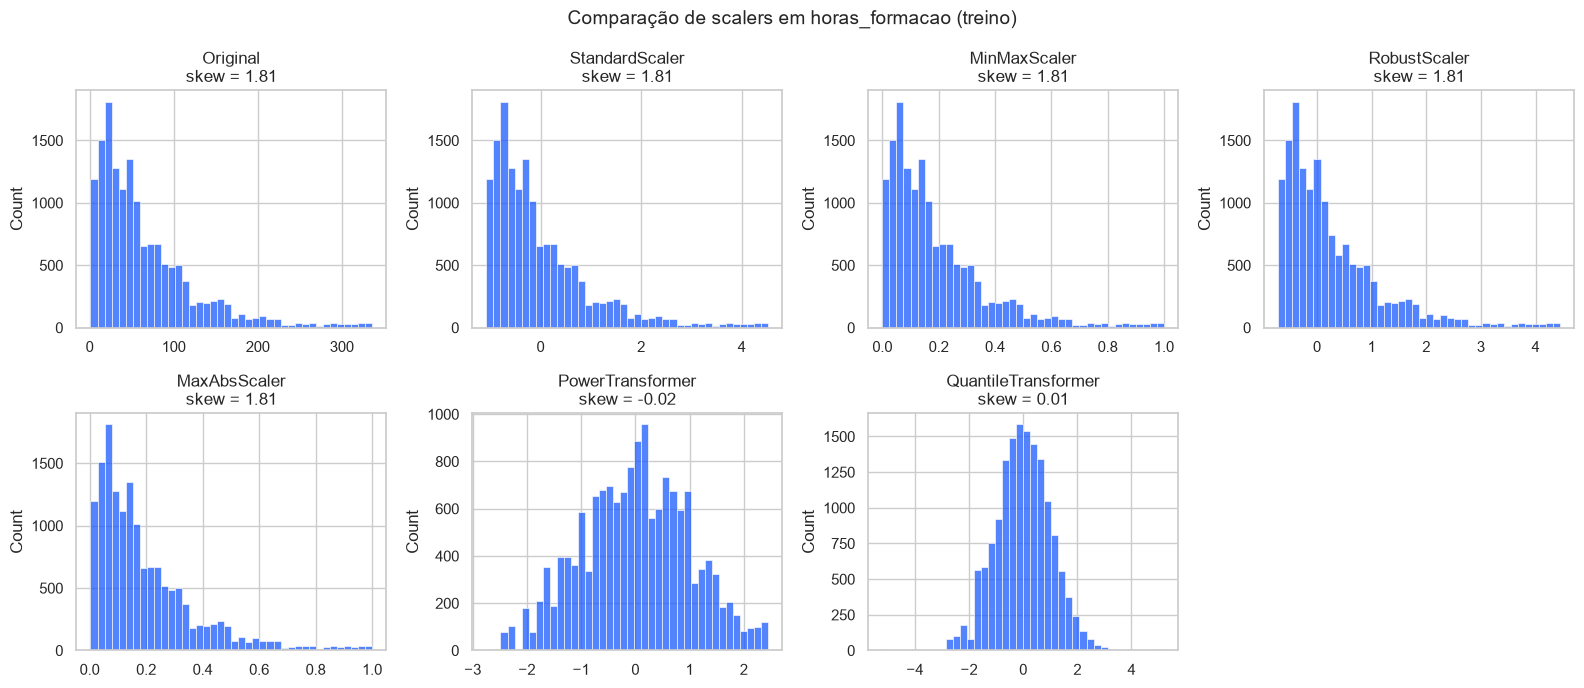

In [50]:
#a variável mais assimétrica e com mais outliers é horas_formacao (skew ~1,8; ~5% de outliers pelo IQR)

from sklearn.preprocessing import MaxAbsScaler, PowerTransformer, QuantileTransformer

COL = "horas_formacao"
x_train = X_train[[COL]]          # [[ ]] -> DataFrame com 1 coluna (os scalers precisam de 2D)

scalers = {
    "StandardScaler":      StandardScaler(),
    "MinMaxScaler":        MinMaxScaler(),
    "RobustScaler":        RobustScaler(),
    "MaxAbsScaler":        MaxAbsScaler(),
    "PowerTransformer":    PowerTransformer(method="yeo-johnson"),
    "QuantileTransformer": QuantileTransformer(output_distribution="normal",
                                               random_state=RANDOM_STATE),
}

# 1. Aplicar cada scaler (fit só no treino)
resultados = {"Original": x_train[COL]}
for nome, scaler in scalers.items():
    resultados[nome] = pd.Series(scaler.fit_transform(x_train).ravel(), index=x_train.index)

# 2. Tabela describe + assimetria
tabela = pd.DataFrame(resultados).describe().T
tabela["skew"] = pd.DataFrame(resultados).skew()
tabela = tabela[["mean", "std", "min", "25%", "50%", "75%", "max", "skew"]].round(2)
print(tabela)

# 3. Histogramas
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (nome, valores) in zip(axes.flat, resultados.items()):
    sns.histplot(valores, bins=40, ax=ax, color="#1A59FD")
    ax.set_title(f"{nome}\nskew = {valores.skew():.2f}")
    ax.set_xlabel("")
axes.flat[-1].axis("off")          # 7 gráficos numa grelha de 8: esconde o último
plt.suptitle(f"Comparação de scalers em {COL} (treino)", fontsize=14)
plt.tight_layout()
guardar_figura("08_comparacao_scalers")
plt.show()

##### Análise e Interpretação

> *Que scaler é mais adequado aos vossos dados e aos modelos que vão usar?*

**Resposta:**

- Compararam-se 6 scalers em `horas_formacao`, a variável mais assimétrica e com mais outliers (skew [1,8]; ~5% de outliers pelo IQR), ajustados apenas no treino.
- **StandardScaler, MinMaxScaler, RobustScaler e MaxAbsScaler só mudam a escala, não a forma:** a assimetria mantém-se ([1,8]) e os histogramas são iguais ao original, apenas com outro eixo.
  - **MinMax e MaxAbs** são os mais afetados pelos outliers: como o máximo é um valor extremo, a maioria dos candidatos fica concentrada perto de 0.
  - **Standard** dá média 0 e desvio 1, mas a média e o desvio-padrão são influenciados pelos outliers.
  - **Robust** usa a mediana e o IQR, pelo que a parte central da distribuição não é "esmagada" pelos extremos; é o mais adequado entre os que mantêm a forma.
- **PowerTransformer e QuantileTransformer mudam a forma:** a assimetria passa para [~0]. O Quantile força uma distribuição quase normal (perde a noção de distância entre valores); o Power é mais suave. O efeito é semelhante ao do `log1p` já aplicado em `horas_formacao_log` (skew [-0,35]).
- **Escolha:** **RobustScaler** para as numéricas, porque nenhuma é normal (Fase 2) e há outliers mantidos de propósito (secção 6.2); a assimetria de `horas_formacao` já é tratada pela variável `horas_formacao_log`. O scaling só será relevante para modelos sensíveis à escala (regressão logística, KNN); as árvores não precisam dele.

<hr>

**8.2 Scaler escolhido**
- Guardar a escolha em `SCALER` (nas aulas: `RobustScaler()`).

In [51]:
# Scaler escolhido (secção 8.1): robusto a outliers e a distribuições assimétricas
SCALER = RobustScaler()

print("Scaler escolhido:", SCALER)
print("Aplicado a:", NUM_COLS)

# Teste rápido no treino (não altera X_train): mediana ~0 e IQR ~1 em cada coluna
teste = pd.DataFrame(
    RobustScaler().fit_transform(X_train[NUM_COLS].fillna(X_train[NUM_COLS].median())),
    columns=NUM_COLS
)
print(teste.describe().loc[["50%", "25%", "75%"]].round(2))

Scaler escolhido: RobustScaler()
Aplicado a: ['indice_desenvolvimento_cidade', 'anos_experiencia', 'anos_desde_ultimo_emprego', 'horas_formacao', 'n_nulos', 'horas_formacao_log']
     indice_desenvolvimento_cidade  anos_experiencia  \
50%                           0.00              0.00   
25%                          -0.94             -0.42   
75%                           0.06              0.58   

     anos_desde_ultimo_emprego  horas_formacao  n_nulos  horas_formacao_log  
50%                        0.0            0.00      0.0                0.00  
25%                        0.0           -0.37     -0.5               -0.53  
75%                        1.0            0.63      0.5                0.47  


- **Scaler escolhido: `RobustScaler`**, aplicado às variáveis numéricas (`NUM_COLS`).
- **Justificação:**
  - Nenhuma das numéricas segue uma distribuição normal (Fase 2, Shapiro-Wilk e QQ-plots), pelo que o pressuposto do `StandardScaler` não se verifica.
  - Os outliers foram mantidos de propósito (secção 6.2). O `RobustScaler` usa a mediana e o IQR, por isso não é distorcido por eles, ao contrário do `StandardScaler` (média e desvio) e sobretudo do `MinMaxScaler` (depende do máximo).
  - Não se escolheu o `PowerTransformer` nem o `QuantileTransformer` porque a correção da assimetria de `horas_formacao` já é feita pela variável `horas_formacao_log`, e o Quantile altera as distâncias entre valores.
- As variáveis binárias (0/1), one-hot e ordinais não são escalonadas.
- O scaler será ajustado **apenas no treino**, dentro do pipeline. É relevante para modelos sensíveis à escala (regressão logística, KNN); para modelos de árvores não tem efeito.

### 9. Redução de dimensionalidade
<hr>

Reduzir o número de variáveis mantendo o máximo de informação (evita overfitting, reduz ruído, melhora velocidade — "maldição da dimensionalidade").

1. **Feature selection** — manter as variáveis mais relevantes (M3.02): correlação > 0,8, baixa variância (`VarianceThreshold`), testes estatísticos (`SelectKBest`), importância de um Random Forest, `RFE`
2. **Feature extraction** — criar novas componentes: **PCA** (sempre depois de escalonar)

***Objetivo:*** reduzir complexidade e multicolinearidade. Em datasets com poucas variáveis, esta etapa pode concluir que **não é necessário reduzir** — também é uma decisão válida.

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Seleção de variáveis e leakage</div>Os métodos que usam o target (<code>SelectKBest</code>, importância do Random Forest, <code>RFE</code>, correlação com o alvo) aplicam-se <b>só no treino</b> — nunca no dataset completo. Mesmo assim, se a seleção for feita aqui sobre todo o treino e depois se fizer validação cruzada na Fase 4 com as variáveis escolhidas, a CV fica <b>ligeiramente otimista</b>, porque os folds de validação já participaram na escolha. A forma mais rigorosa é colocar a seleção dentro do Pipeline (ex.: passo <code>SelectKBest</code>, com <code>k</code> afinado no GridSearch). Se a fizerem aqui, mencionem esta limitação na Fase 5.</div>

**9.1 Variância baixa**
- `VarianceThreshold` nas numéricas do treino; listar as variáveis quase constantes.

In [52]:
# 1. Preparar as numéricas + binárias do treino (sem nulos e na escala 0-1)
cols_var = NUM_COLS + BIN_COLS
dados = X_train[cols_var].fillna(X_train[cols_var].median())      # o VarianceThreshold não aceita nulos
dados_01 = pd.DataFrame(MinMaxScaler().fit_transform(dados), columns=cols_var, index=dados.index)

# 2. VarianceThreshold com limite 0,01 (na escala 0-1)
LIMIAR_VAR = 0.01
vt = VarianceThreshold(threshold=LIMIAR_VAR).fit(dados_01)

# 3. Tabela: variância (0-1), % do valor mais frequente e se passa o limite
var_tabela = pd.DataFrame({
    "variancia_0a1": dados_01.var().round(4),
    "pct_valor_mais_frequente": (dados.apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(1),
    "mantida": vt.get_support(),
}).sort_values("variancia_0a1")
print(var_tabela)

quase_constantes = var_tabela.index[~var_tabela["mantida"]].tolist()
print("\nVariáveis quase constantes (numéricas/binárias):", quase_constantes or "nenhuma")

                               variancia_0a1  pct_valor_mais_frequente  \
horas_formacao                        0.0319                       1.7   
n_nulos                               0.0324                      46.7   
horas_formacao_log                    0.0339                       1.7   
indice_desenvolvimento_cidade         0.0606                      27.4   
anos_experiencia                      0.1040                      17.2   
nunca_mudou_emprego                   0.1103                      87.4   
anos_desde_ultimo_emprego             0.1109                      44.1   
empresa_em_falta                      0.2280                      64.8   

                               mantida  
horas_formacao                    True  
n_nulos                           True  
horas_formacao_log                True  
indice_desenvolvimento_cidade     True  
anos_experiencia                  True  
nunca_mudou_emprego               True  
anos_desde_ultimo_emprego         True  
empre

In [53]:
vt_ohe = VarianceThreshold(threshold=LIMIAR_VAR).fit(X_train_ohe)
ohe_baixa = pd.DataFrame({
    "variancia": X_train_ohe.var().round(4),
    "pct_de_1": (X_train_ohe.mean() * 100).round(2),
})[~vt_ohe.get_support()]
print("Colunas one-hot abaixo do limite:")
print(ohe_baixa if len(ohe_baixa) else "nenhuma")

Colunas one-hot abaixo do limite:
                    variancia  pct_de_1
tipo_empresa_Outro      0.006      0.61


##### Análise e Interpretação

> *Há variáveis que quase não variam?*

**Resposta:**

- **Nas numéricas e binárias, não há variáveis quase constantes.** Depois de passar tudo para a escala 0–1 (necessário porque a variância depende da escala; sem isto, `indice_desenvolvimento_cidade` seria falsamente marcado por ter valores entre 0 e 1), todas têm variância acima do limite de 0,01 e em nenhuma o valor mais frequente ultrapassa 87.4 % dos candidatos.
- **Nas colunas one-hot**, nenhuma fica abaixo do limite: mesmo as categorias menos frequentes têm variância suficiente.

- O `VarianceThreshold` não usa o alvo, por isso não há risco de data leakage; foi ajustado apenas no treino.

<hr>

**9.2 Correlação entre preditores**
- Listar os pares com |r| > 0,8 no treino.

In [54]:
# 1. Juntar tudo o que o modelo vai receber (versões codificadas do treino)
X_corr = pd.concat([
    X_train[NUM_COLS].fillna(X_train[NUM_COLS].median()),
    X_train[BIN_COLS],
    X_train_ordenc,          # ordinais codificadas (7.4)
    X_train_ohe,             # one-hot (7.2)
], axis=1)
print("Colunas analisadas:", X_corr.shape[1])

# 2. Matriz de correlação (só no treino) e pares com |r| > 0,8
LIMIAR_CORR = 0.8
corr = X_corr.corr()

pares = []
cols = corr.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):          # só metade da matriz (evita repetir pares)
        r = corr.iloc[i, j]
        if abs(r) > LIMIAR_CORR:
            pares.append({"var_1": cols[i], "var_2": cols[j], "r": round(r, 3)})

pares_altos = pd.DataFrame(pares)
if len(pares_altos):
    pares_altos = pares_altos.sort_values("r", key=abs, ascending=False)
print(f"\nPares com |r| > {LIMIAR_CORR}:")
print(pares_altos if len(pares_altos) else "nenhum")

Colunas analisadas: 42

Pares com |r| > 0.8:
                       var_1                      var_2      r
0           anos_experiencia        escalao_experiencia  0.950
5           empresa_em_falta      tipo_empresa_Em falta  0.934
4           empresa_em_falta  dimensao_empresa_Em falta  0.913
1             horas_formacao         horas_formacao_log  0.864
7  dimensao_empresa_Em falta      tipo_empresa_Em falta  0.836
6            genero_Em falta           genero_Masculino -0.827
2                    n_nulos           empresa_em_falta  0.810
3                    n_nulos  dimensao_empresa_Em falta  0.803


Figura guardada em: Data\analytics\09_correlacao_preditores.png


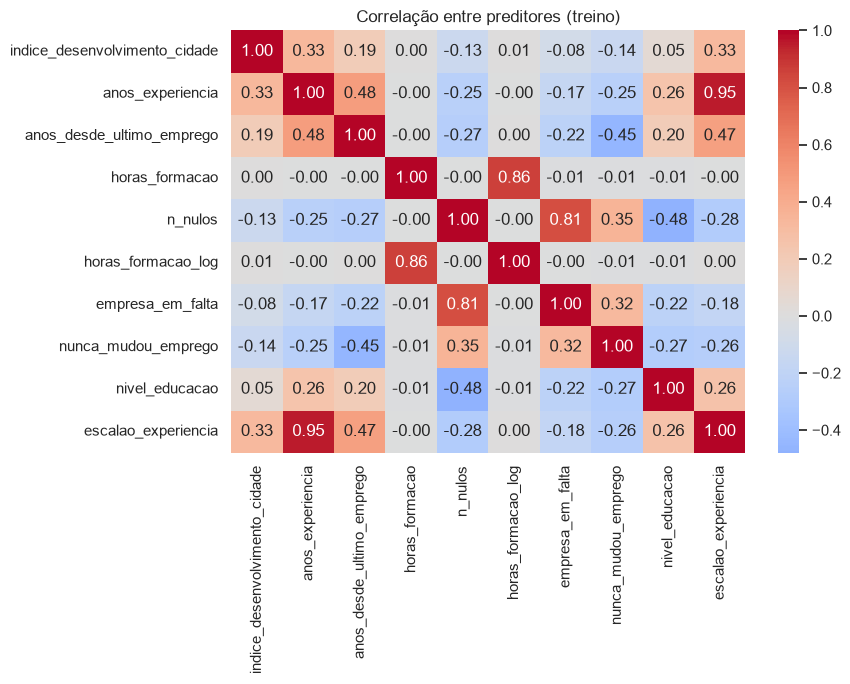

In [55]:
cols_heat = NUM_COLS + BIN_COLS + ORD_COLS
plt.figure(figsize=(9, 7))
sns.heatmap(X_corr[cols_heat].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre preditores (treino)")
plt.tight_layout()
guardar_figura("09_correlacao_preditores")
plt.show()

In [56]:
COLS_REDUNDANTES = [
    "horas_formacao",        # fica horas_formacao_log (mesma info, menos assimétrica)
    "escalao_experiencia",   # fica anos_experiencia (mesma ordem, mais detalhe, sem "Em falta" na escala)
]
# Se empresa_em_falta aparecer na lista de pares com |r| > 0,8, acrescenta-a aqui:
# "empresa_em_falta",    # a informação fica nas categorias "Em falta" do one-hot

X_train = X_train.drop(columns=COLS_REDUNDANTES)
X_test  = X_test.drop(columns=COLS_REDUNDANTES)

# Atualizar as listas
NUM_COLS = [c for c in NUM_COLS if c not in COLS_REDUNDANTES]
BIN_COLS = [c for c in BIN_COLS if c not in COLS_REDUNDANTES]
ORD_COLS = [c for c in ORD_COLS if c not in COLS_REDUNDANTES]
NOM_COLS = [c for c in NOM_COLS if c not in COLS_REDUNDANTES]
CAT_COLS = ORD_COLS + NOM_COLS
ORDENS   = {c: o for c, o in ORDENS.items() if c in ORD_COLS}

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("NUM_COLS:", NUM_COLS)
print("BIN_COLS:", BIN_COLS)
print("ORD_COLS:", ORD_COLS)
print("NOM_COLS:", NOM_COLS)

X_train: (15326, 14) | X_test: (3832, 14)
NUM_COLS: ['indice_desenvolvimento_cidade', 'anos_experiencia', 'anos_desde_ultimo_emprego', 'n_nulos', 'horas_formacao_log']
BIN_COLS: ['empresa_em_falta', 'nunca_mudou_emprego']
ORD_COLS: ['nivel_educacao']
NOM_COLS: ['genero', 'experiencia_relevante', 'inscricao_universidade', 'area_formacao', 'dimensao_empresa', 'tipo_empresa']


##### Análise e Interpretação

> *Que variáveis redundantes podem ser removidas?*

**Resposta:**

- Calculou-se a correlação no treino entre todos os preditores que o modelo vai receber (numéricas, binárias, ordinais codificadas e colunas one-hot).
  - `anos_experiencia` ↔ `escalao_experiencia` o escalão é a mesma variável agrupada.
  - `horas_formacao` ↔ `horas_formacao_log`  o log é a mesma variável transformada.
  - [Se aparecer:] `empresa_em_falta` ↔ `[dimensao_empresa_Em falta]` : o indicador repete a categoria "Em falta" do one-hot.
- São redundâncias **esperadas**, criadas na engenharia de variáveis (secção 4.1) para comparar versões; nas variáveis originais não há multicolinearidade (confirma a Fase 2, secção 5.4).
- **Variáveis removidas:**
  - `horas_formacao` → mantém-se `horas_formacao_log`, com a mesma informação e menos assimetria (melhor para a regressão logística; indiferente para árvores).
  - `escalao_experiencia` → mantém-se `anos_experiencia`, com a mesma ordem e mais detalhe, sem a categoria "Em falta" encaixada na escala.
 
- A remoção foi aplicada da mesma forma a `X_train` e `X_test`, e as listas de colunas foram atualizadas. Esta seleção não usa o alvo (só correlações entre preditores), pelo que não há risco de data leakage.

- 

<hr>

**9.3 Seleção por teste e por modelo (M3.02)**
- Sobre os dados de treino imputados e codificados: `SelectKBest` (`f_classif` / `f_regression`), importância de um Random Forest (`feature_importances_`) e `RFE` com Logistic/Linear Regression.
- Tabela comparativa.

In [57]:
from sklearn.ensemble import RandomForestClassifier

# 1. Numéricas: mediana + RobustScaler (o RFE com regressão logística precisa de escala)
num_imp = SimpleImputer(strategy=ESTRATEGIA_NUM).fit(X_train[NUM_COLS])
num_esc = RobustScaler().fit(num_imp.transform(X_train[NUM_COLS]))
M_num = pd.DataFrame(num_esc.transform(num_imp.transform(X_train[NUM_COLS])),
                     columns=NUM_COLS, index=X_train.index)

# 2. Binárias: passam como estão
M_bin = X_train[BIN_COLS]

# 3. Ordinais: "Em falta" + OrdinalEncoder
ord_enc = OrdinalEncoder(categories=[ORDENS[c] for c in ORD_COLS]).fit(
    X_train[ORD_COLS].fillna(FILL_VALUE_CAT))
M_ord = pd.DataFrame(ord_enc.transform(X_train[ORD_COLS].fillna(FILL_VALUE_CAT)),
                     columns=ORD_COLS, index=X_train.index)

# 4. Nominais: "Em falta" + OneHotEncoder
ohe = OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False).fit(
    X_train[NOM_COLS].fillna(FILL_VALUE_CAT))
M_ohe = pd.DataFrame(ohe.transform(X_train[NOM_COLS].fillna(FILL_VALUE_CAT)),
                     columns=ohe.get_feature_names_out(NOM_COLS), index=X_train.index)

X_train_prep = pd.concat([M_num, M_bin, M_ord, M_ohe], axis=1)
print("Matriz de treino preparada:", X_train_prep.shape)

Matriz de treino preparada: (15326, 40)


In [58]:
# A. SelectKBest com f_classif (teste ANOVA: as médias das classes diferem?)
skb = SelectKBest(score_func=f_classif, k="all").fit(X_train_prep, y_train)

# B. Importância num Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE,
                            class_weight="balanced", n_jobs=-1)
rf.fit(X_train_prep, y_train)

# C. RFE com regressão logística: elimina variáveis uma a uma até ficarem N_RFE
N_RFE = 15
rfe = RFE(LogisticRegression(max_iter=1000, class_weight="balanced"),
          n_features_to_select=N_RFE).fit(X_train_prep, y_train)

# Tabela comparativa
selecao = pd.DataFrame({
    "F_score":       skb.scores_.round(1),
    "p_valor":       skb.pvalues_,
    "importancia_RF": rf.feature_importances_.round(4),
    "RFE_ranking":   rfe.ranking_,          # 1 = selecionada
    "RFE_selec":     rfe.support_,
}, index=X_train_prep.columns)

# Posição (1 = melhor) em cada método e posição média
selecao["pos_F"]  = selecao["F_score"].rank(ascending=False).astype(int)
selecao["pos_RF"] = selecao["importancia_RF"].rank(ascending=False).astype(int)
selecao["pos_RFE"] = selecao["RFE_ranking"].rank(method="min").astype(int)
selecao["pos_media"] = selecao[["pos_F", "pos_RF", "pos_RFE"]].mean().round(1) if False else \
                       selecao[["pos_F", "pos_RF", "pos_RFE"]].mean(axis=1).round(1)
selecao = selecao.sort_values("pos_media")

pd.set_option("display.float_format", lambda v: f"{v:.4g}")
selecao

,F_score,p_valor,importancia_RF,RFE_ranking,RFE_selec,pos_F,pos_RF,pos_RFE,pos_media
indice_desenvolvimento_cidade,2077,0,0.2577,1,True,1,1,1,1
anos_experiencia,518.9,5.381e-113,0.1328,1,True,6,3,1,3.3
dimensao_empresa_Em falta,1022,4.191e-217,0.0248,1,True,2,7,1,3.3
empresa_em_falta,832.8,2.27e-178,0.019,1,True,3,8,1,4
tipo_empresa_Em falta,817.7,2.969e-175,0.016,1,True,4,10,1,5
inscricao_universidade_Curso a tempo inteiro,417.3,1.597e-91,0.0125,1,True,8,12,1,7
dimensao_empresa_50 a 99,100.7,1.251e-23,0.0106,1,True,12,15,1,9.3
dimensao_empresa_100 a 500,100.2,1.597e-23,0.01,1,True,13,17,1,10.3
experiencia_relevante_Sem experiência relevante,286,1.41e-63,0.0186,4,False,10,9,18,12.3
nunca_mudou_emprego,37.2,1.065e-09,0.0087,1,True,18,19,1,12.7


##### Análise e Interpretação

> *Que variáveis aparecem como importantes em todos os métodos? Onde discordam e porquê?*

**Resposta:**

- Aplicaram-se três métodos de seleção sobre o treino imputado e codificado: `SelectKBest` com `f_classif`, importância de um Random Forest e `RFE` com regressão logística (15 variáveis).
- **Concordância no topo:** os três métodos colocam entre as mais relevantes `indice_desenvolvimento_cidade`, as categorias "Em falta" de `dimensao_empresa`/`tipo_empresa`, `n_nulos`, `anos_experiencia`, [`experiencia_relevante`, `inscricao_universidade_...`]. Confirma a Fase 2 (índice com efeito grande, H2; dados em falta associados ao alvo, H6; experiência, H1 e H4).
- **Concordância no fundo:** colunas de `genero`, `area_formacao` e categorias raras têm F baixo, pouca importância e são eliminadas pelo RFE (também coerente com os V de Cramér baixos da Fase 2).
- **Diferenças:** [`horas_formacao_log`] tem importância elevada no Random Forest mas F baixo. A importância do RF favorece variáveis contínuas (muitos pontos de corte possíveis), pelo que sobrevaloriza as numéricas; o F avalia cada variável isoladamente e o RFE tem em conta as outras variáveis num modelo linear. Por isso nenhum método deve ser usado sozinho.
- **Decisão: manter todas as variáveis nesta fase.** O número de colunas é pequeno face às ~15 000 linhas de treino, e as variáveis fracas podem ser úteis em combinação. A seleção fina (ex.: `SelectKBest` com `k` afinado) poderá ser feita dentro do Pipeline na Fase 4.
- **Limitação:** estes métodos usam o alvo; foram aplicados só no treino, mas, se a seleção fosse fixada aqui, a validação cruzada da Fase 4 ficaria ligeiramente otimista (os folds de validação teriam participado na escolha). A mencionar na Fase 5.

<hr>

**9.4 PCA**
- Normalizar as numéricas do treino e aplicar `PCA()`; tabela da variância explicada e acumulada; nº de componentes para ≥ 95%; gráfico da variância acumulada.

            var_explicada_%  var_acumulada_%
componente                                  
PC1                    37.1             37.1
PC2                      20             57.1
PC3                    17.7             74.8
PC4                    15.3             90.1
PC5                     9.9              100

Componentes para >= 95%: 5 de 5 variáveis (poupam-se 0)

Loadings:
componente                      PC1   PC2   PC3  PC4   PC5
indice_desenvolvimento_cidade  0.42  0.03  0.71 -0.5 -0.26
anos_experiencia               0.59 -0.01  0.13 0.29  0.74
anos_desde_ultimo_emprego      0.55 -0.01 -0.18 0.53 -0.62
n_nulos                       -0.41  0.01  0.67 0.62 -0.03
horas_formacao_log                0     1 -0.03 0.01  0.01
Figura guardada em: Data\analytics\09_pca_variancia_numericas.png


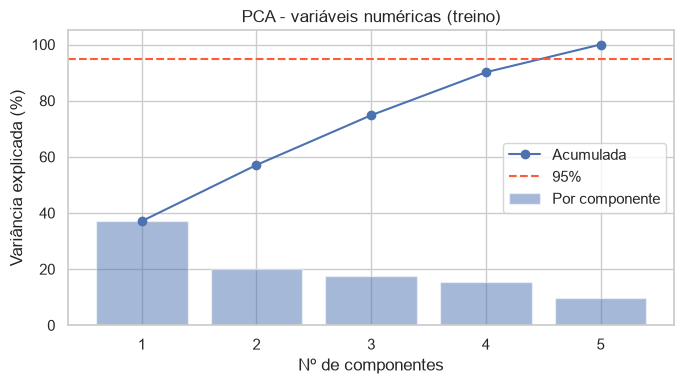

In [60]:
# 1. Imputar (mediana) e normalizar as numéricas do treino
num_pca = SimpleImputer(strategy=ESTRATEGIA_NUM).fit_transform(X_train[NUM_COLS])
num_pca = StandardScaler().fit_transform(num_pca)     # PCA usa a variância -> escala igual

# 2. PCA com todos os componentes
pca_num = PCA(random_state=RANDOM_STATE).fit(num_pca)

var_tab = pd.DataFrame({
    "componente": [f"PC{i+1}" for i in range(pca_num.n_components_)],
    "var_explicada_%": (pca_num.explained_variance_ratio_ * 100).round(1),
    "var_acumulada_%": (pca_num.explained_variance_ratio_.cumsum() * 100).round(1),
}).set_index("componente")
print(var_tab)

n_95 = int(np.argmax(pca_num.explained_variance_ratio_.cumsum() >= 0.95) + 1)
print(f"\nComponentes para >= 95%: {n_95} de {len(NUM_COLS)} variáveis "
      f"(poupam-se {len(NUM_COLS) - n_95})")

# 3. Loadings (o que "é" cada componente)
loadings = pd.DataFrame(pca_num.components_.T, index=NUM_COLS,
                        columns=var_tab.index).round(2)
print("\nLoadings:")
print(loadings)

# 4. Gráfico da variância acumulada
plt.figure(figsize=(7, 4))
x = range(1, pca_num.n_components_ + 1)
plt.bar(x, pca_num.explained_variance_ratio_ * 100, alpha=0.5, label="Por componente")
plt.plot(x, pca_num.explained_variance_ratio_.cumsum() * 100, marker="o", label="Acumulada")
plt.axhline(95, color="#FF5B34", linestyle="--", label="95%")
plt.xticks(x)
plt.xlabel("Nº de componentes")
plt.ylabel("Variância explicada (%)")
plt.title("PCA - variáveis numéricas (treino)")
plt.legend()
plt.tight_layout()
guardar_figura("09_pca_variancia_numericas")
plt.show()

Todas as colunas: 40 -> 29 componentes para >= 95% (poupam-se 11)
Figura guardada em: Data\analytics\09_pca_variancia_todas.png


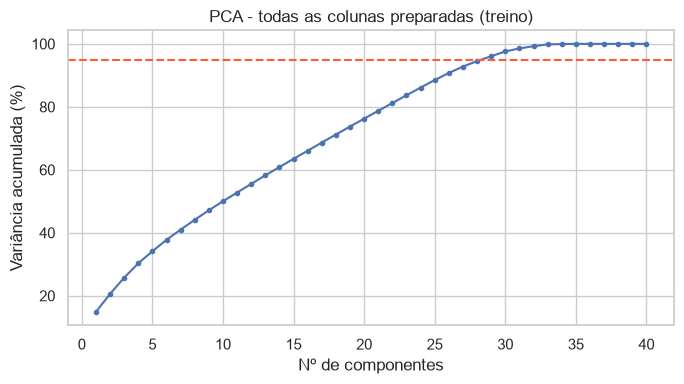

In [61]:
todas_esc = StandardScaler().fit_transform(X_train_prep)
pca_all = PCA(random_state=RANDOM_STATE).fit(todas_esc)
acum = pca_all.explained_variance_ratio_.cumsum()

n_95_all = int(np.argmax(acum >= 0.95) + 1)
print(f"Todas as colunas: {X_train_prep.shape[1]} -> {n_95_all} componentes para >= 95% "
      f"(poupam-se {X_train_prep.shape[1] - n_95_all})")

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(acum) + 1), acum * 100, marker=".")
plt.axhline(95, color="#FF5B34", linestyle="--")
plt.xlabel("Nº de componentes"); plt.ylabel("Variância acumulada (%)")
plt.title("PCA - todas as colunas preparadas (treino)")
plt.tight_layout()
guardar_figura("09_pca_variancia_todas")
plt.show()

##### Análise e Interpretação

> *Vale a pena usar PCA? Quantas variáveis se poupariam e o que se perde em interpretabilidade?*

**Resposta:**

- **Nas variáveis numéricas** (5, depois da remoção das redundâncias na secção 9.2), são precisos **5 componentes** para explicar ≥ 95% da variância: poupar-se-ia apenas 0 variáveis. A variância está repartida de forma relativamente uniforme (PC1 explica só 95 %), porque as variáveis numéricas estão pouco correlacionadas entre si: cada uma traz informação própria.

- **O que se perde em interpretabilidade:** cada componente é uma mistura de todas as variáveis. Deixava de ser possível dizer ao negócio "candidatos de cidades menos desenvolvidas, sem experiência e sem dados da empresa procuram mais mudar", que é precisamente a leitura útil para RH. As colunas one-hot, em particular, perdem completamente o significado.
- **Decisão: não usar PCA.** O dataset tem poucas variáveis para o número de linhas (~15 000 linhas de treino), não há multicolinearidade depois da secção 9.2, e o ganho em dimensionalidade é mínimo face à perda de interpretabilidade. Além disso, os modelos baseados em árvores não beneficiam do PCA. Na Fase 2 (secção 6.4), a projeção em 2 componentes também não mostrou separação entre classes.

- 

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Critério da variância acumulada: 70–80% (redução agressiva, exploração) · 85–90% (bom equilíbrio) · <b>95%</b> (conservador, muito usado) · 99% (perda mínima). Uma redução começa a ser interessante quando se reduzem 40–50% das variáveis mantendo 90–95% da variância. <b>Seleção</b> mantém variáveis interpretáveis; o <b>PCA</b> mantém mais informação mas as componentes perdem significado (M3.02).</div>

**9.5 Decisão**
- Atualizar `NUM_COLS`/`CAT_COLS` com as variáveis a remover e definir `USAR_PCA` (True/False).

In [62]:
# Decisões da secção 9
COLS_REMOVIDAS_SELECAO = []        # 9.1 e 9.3: nenhuma remoção adicional
USAR_PCA = False                   # 9.4: ganho mínimo, perda de interpretabilidade

# (As redundâncias já foram removidas na 9.2 - ficam registadas em COLS_REDUNDANTES)
print("Removidas por redundância (9.2):", COLS_REDUNDANTES)
print("Removidas por seleção (9.1/9.3):", COLS_REMOVIDAS_SELECAO or "nenhuma")
print("USAR_PCA:", USAR_PCA)

# Aplicar remoções adicionais, se existirem (com proteção contra repetição)
if COLS_REMOVIDAS_SELECAO:
    a_remover = [c for c in COLS_REMOVIDAS_SELECAO if c in X_train.columns]
    X_train = X_train.drop(columns=a_remover)
    X_test  = X_test.drop(columns=a_remover)

# Listas finais
NUM_COLS = [c for c in NUM_COLS if c in X_train.columns]
BIN_COLS = [c for c in BIN_COLS if c in X_train.columns]
ORD_COLS = [c for c in ORD_COLS if c in X_train.columns]
NOM_COLS = [c for c in NOM_COLS if c in X_train.columns]
CAT_COLS = ORD_COLS + NOM_COLS

print("\nNUM_COLS:", NUM_COLS)
print("BIN_COLS:", BIN_COLS)
print("ORD_COLS:", ORD_COLS)
print("NOM_COLS:", NOM_COLS)

# Verificações finais
todas = NUM_COLS + BIN_COLS + CAT_COLS
print("\nTodas as colunas de X_train estão numa lista?", sorted(todas) == sorted(X_train.columns))
print("X_train e X_test com as mesmas colunas?", list(X_train.columns) == list(X_test.columns))
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Removidas por redundância (9.2): ['horas_formacao', 'escalao_experiencia']
Removidas por seleção (9.1/9.3): nenhuma
USAR_PCA: False

NUM_COLS: ['indice_desenvolvimento_cidade', 'anos_experiencia', 'anos_desde_ultimo_emprego', 'n_nulos', 'horas_formacao_log']
BIN_COLS: ['empresa_em_falta', 'nunca_mudou_emprego']
ORD_COLS: ['nivel_educacao']
NOM_COLS: ['genero', 'experiencia_relevante', 'inscricao_universidade', 'area_formacao', 'dimensao_empresa', 'tipo_empresa']

Todas as colunas de X_train estão numa lista? True
X_train e X_test com as mesmas colunas? True
X_train: (15326, 14) | X_test: (3832, 14)


### 10. Pipeline final de preparação
<hr>

O `Pipeline` + `ColumnTransformer` junta todas as decisões anteriores num único objeto que:
- evita *data leakage* (é ajustado só no treino — e, na Fase 4, dentro de cada fold da validação cruzada);
- aplica exatamente as mesmas transformações a treino, teste e dados futuros;
- torna o processo reproduzível.

**10.1 Pipeline final de preparação (M3.02)**
- `ColumnTransformer` com:
  - `"num"`: `Pipeline` com imputação (`SimpleImputer(strategy=ESTRATEGIA_NUM, add_indicator=ADD_INDICATOR)`, ou `KNNImputer` se `"knn"`) + `SCALER` (+ PCA se `USAR_PCA`);
  - `"cat"`: `Pipeline` com imputação (`ESTRATEGIA_CAT`) + `OneHotEncoder(handle_unknown="ignore")`.
- `fit_transform` no treino e `transform` no teste; mostrar as dimensões e as primeiras linhas.

In [63]:
from sklearn.base import clone

# --- Ramo numérico: imputação + scaling (+ PCA, se escolhido) ---
if ESTRATEGIA_NUM == "knn":
    imputer_num = KNNImputer(n_neighbors=5, add_indicator=ADD_INDICATOR)
else:
    imputer_num = SimpleImputer(strategy=ESTRATEGIA_NUM, add_indicator=ADD_INDICATOR)

passos_num = [("imputer", imputer_num), ("scaler", clone(SCALER))]
if USAR_PCA:
    passos_num.append(("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)))
pipe_num = Pipeline(passos_num)

# --- Ramo ordinal: "Em falta" + OrdinalEncoder com ordem explícita ---
pipe_ord = Pipeline([
    ("imputer", SimpleImputer(strategy=ESTRATEGIA_CAT, fill_value=FILL_VALUE_CAT)),
    ("encoder", OrdinalEncoder(categories=[ORDENS[c] for c in ORD_COLS],
                               handle_unknown="use_encoded_value", unknown_value=-1)),
])

# --- Ramo nominal: "Em falta" + OneHotEncoder ---
pipe_nom = Pipeline([
    ("imputer", SimpleImputer(strategy=ESTRATEGIA_CAT, fill_value=FILL_VALUE_CAT)),
    ("encoder", OneHotEncoder(handle_unknown="ignore", drop="if_binary",
                              sparse_output=False)),
])

# --- ColumnTransformer: cada lista de colunas vai para o seu ramo ---
preprocessador = ColumnTransformer([
    ("num", pipe_num, NUM_COLS),
    ("bin", "passthrough", BIN_COLS),   # 0/1 sem nulos: passam como estão
    ("ord", pipe_ord, ORD_COLS),
    ("nom", pipe_nom, NOM_COLS),
], remainder="drop", verbose_feature_names_out=False)

preprocessador.set_output(transform="pandas")   # devolve DataFrames com nomes de colunas

# --- fit_transform no treino, transform no teste ---
X_train_prep = preprocessador.fit_transform(X_train)   # aprende E aplica
X_test_prep  = preprocessador.transform(X_test)        # só aplica (com o que aprendeu no treino)

print("X_train_prep:", X_train_prep.shape)
print("X_test_prep: ", X_test_prep.shape)
print("Nulos restantes (treino/teste):", X_train_prep.isna().sum().sum(), "/", X_test_prep.isna().sum().sum())
print("Mesmas colunas em treino e teste?", list(X_train_prep.columns) == list(X_test_prep.columns))
X_train_prep.head()


X_train_prep: (15326, 40)
X_test_prep:  (3832, 40)
Nulos restantes (treino/teste): 0 / 0
Mesmas colunas em treino e teste? True


,indice_desenvolvimento_cidade,anos_experiencia,anos_desde_ultimo_emprego,n_nulos,horas_formacao_log,empresa_em_falta,nunca_mudou_emprego,nivel_educacao,genero_Em falta,genero_Feminino,genero_Masculino,genero_Outro,experiencia_relevante_Sem experiência relevante,inscricao_universidade_Curso a tempo inteiro,inscricao_universidade_Curso a tempo parcial,inscricao_universidade_Em falta,inscricao_universidade_Não inscrito,area_formacao_Artes,"area_formacao_Ciência, Tecnologia, Engenharia e Matemática",area_formacao_Em falta,area_formacao_Gestão e Negócios,area_formacao_Humanidades,area_formacao_Outro,area_formacao_Sem especialização,dimensao_empresa_10 a 49,dimensao_empresa_100 a 500,dimensao_empresa_1000 a 4999,dimensao_empresa_10000 ou mais,dimensao_empresa_50 a 99,dimensao_empresa_500 a 999,dimensao_empresa_5000 a 9999,dimensao_empresa_Em falta,dimensao_empresa_Menos de 10,tipo_empresa_Em falta,tipo_empresa_Empresa privada,tipo_empresa_ONG,tipo_empresa_Outro,tipo_empresa_Setor público,tipo_empresa_Startup em fase inicial,tipo_empresa_Startup financiada
id_candidato,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
966838,-1.589,-0.4167,0,-0.5,0.3992,0,0,3,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0
675381,0.08889,1,2,-0.5,0.3802,0,0,3,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0
927526,0,-0.25,0,0.5,1.262,1,0,2,0,0,1,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0
239005,0,1,2,-0.5,0.1444,0,0,3,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0
392878,-2.128,0,0,-0.5,0.1574,0,0,4,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


In [64]:
num = preprocessador.named_transformers_["num"]
print("Medianas (imputação):", dict(zip(NUM_COLS, num.named_steps["imputer"].statistics_.round(2))))
print("Medianas (scaler):  ", dict(zip(NUM_COLS, num.named_steps["scaler"].center_.round(2))))
print("IQR (scaler):       ", dict(zip(NUM_COLS, num.named_steps["scaler"].scale_.round(2))))

nom = preprocessador.named_transformers_["nom"]
print("\nCategorias one-hot aprendidas:")
for col, cats in zip(NOM_COLS, nom.named_steps["encoder"].categories_):
    print(f"  {col}: {list(cats)}")

Medianas (imputação): {'indice_desenvolvimento_cidade': np.float64(0.91), 'anos_experiencia': np.float64(9.0), 'anos_desde_ultimo_emprego': np.float64(1.0), 'n_nulos': np.float64(1.0), 'horas_formacao_log': np.float64(3.87)}
Medianas (scaler):   {'indice_desenvolvimento_cidade': np.float64(0.91), 'anos_experiencia': np.float64(9.0), 'anos_desde_ultimo_emprego': np.float64(1.0), 'n_nulos': np.float64(1.0), 'horas_formacao_log': np.float64(3.87)}
IQR (scaler):        {'indice_desenvolvimento_cidade': np.float64(0.18), 'anos_experiencia': np.float64(12.0), 'anos_desde_ultimo_emprego': np.float64(2.0), 'n_nulos': np.float64(2.0), 'horas_formacao_log': np.float64(1.31)}

Categorias one-hot aprendidas:
  genero: ['Em falta', 'Feminino', 'Masculino', 'Outro']
  experiencia_relevante: ['Com experiência relevante', 'Sem experiência relevante']
  inscricao_universidade: ['Curso a tempo inteiro', 'Curso a tempo parcial', 'Em falta', 'Não inscrito']
  area_formacao: ['Artes', 'Ciência, Tecnologia,

##### Análise e Interpretação

> *Quantas colunas tem o dataset preparado? O que foi aprendido no treino e aplicado ao teste?*

**Resposta:**

**Resposta:**

- **O dataset preparado tem 40 colunas** (treino: 15 326 × 40; teste: 3 832 × 40), sem nulos e com exatamente as mesmas colunas em treino e teste:
  - 5 numéricas (imputação pela mediana + `RobustScaler`);
  - 2 binárias (`empresa_em_falta`, `nunca_mudou_emprego`), que passam sem alterações;
  - 1 ordinal (`nivel_educacao`, "Em falta" + `OrdinalEncoder` com ordem explícita);
  - 30 colunas one-hot, resultantes das 6 nominais ("Em falta" + `OneHotEncoder`).
- **O que foi aprendido no treino** (`fit_transform`) e aplicado ao teste (`transform`):
  - as **medianas** usadas para preencher os nulos das numéricas 
  - a **mediana e o IQR** de cada numérica, usados pelo `RobustScaler`;
  - as **categorias** de cada variável nominal, que definem as colunas one-hot (categorias novas no teste ficam a 0 graças a `handle_unknown="ignore"`);
  - no ordinal, a ordem não é aprendida (foi definida por nós), mas as categorias são validadas.
- O teste **nunca foi usado para calcular nada**: só recebeu as transformações aprendidas no treino, o que evita data leakage. O PCA não foi incluído (`USAR_PCA = False`).
- O pipeline garante que treino, teste e dados futuros são transformados exatamente da mesma forma e, na Fase 4, será ajustado dentro de cada fold da validação cruzada.

<hr>

**10.2 Verificação**
- Confirmar que não há valores em falta nos dados preparados.

In [65]:
def verificar(nome, Xp, y_):
    print(f"===== {nome} =====")
    print("Dimensão:", Xp.shape)
    print("Valores em falta:", int(Xp.isna().sum().sum()))
    print("Valores infinitos:", int(np.isinf(Xp.to_numpy(dtype=float)).sum()))
    print("Todas as colunas numéricas?", all(pd.api.types.is_numeric_dtype(t) for t in Xp.dtypes))
    print("Índice alinhado com y?", Xp.index.equals(y_.index))
    print()

verificar("Treino", X_train_prep, y_train)
verificar("Teste",  X_test_prep,  y_test)

print("Mesmas colunas, pela mesma ordem?", list(X_train_prep.columns) == list(X_test_prep.columns))

# Colunas com nulos (se houver, aparecem aqui)
nulos_cols = X_test_prep.columns[X_test_prep.isna().any()].tolist() + \
             X_train_prep.columns[X_train_prep.isna().any()].tolist()
print("Colunas com nulos:", nulos_cols or "nenhuma")

# Controlo de coerência: binárias/one-hot só com 0 e 1; numéricas com mediana ~0 no treino
cols_01 = [c for c in X_train_prep.columns if c not in NUM_COLS + ORD_COLS]
print("\nBinárias e one-hot só com 0/1?",
      set(np.unique(X_train_prep[cols_01].to_numpy())) <= {0, 1})
print("Medianas das numéricas no treino (devem ser ~0):")
print(X_train_prep[NUM_COLS].median().round(3))
print("\nCódigos de nivel_educacao (treino):", sorted(X_train_prep["nivel_educacao"].unique()))

===== Treino =====
Dimensão: (15326, 40)
Valores em falta: 0
Valores infinitos: 0
Todas as colunas numéricas? True
Índice alinhado com y? True

===== Teste =====
Dimensão: (3832, 40)
Valores em falta: 0
Valores infinitos: 0
Todas as colunas numéricas? True
Índice alinhado com y? True

Mesmas colunas, pela mesma ordem? True
Colunas com nulos: nenhuma

Binárias e one-hot só com 0/1? True
Medianas das numéricas no treino (devem ser ~0):
indice_desenvolvimento_cidade   0
anos_experiencia                0
anos_desde_ultimo_emprego       0
n_nulos                         0
horas_formacao_log              0
dtype: float64

Códigos de nivel_educacao (treino): [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


### 11. Exportação dos dados preparados
<hr>

Gravam-se em `Data/output/`:
- `*_train.csv` / `*_test.csv` — dados **após limpeza e feature engineering, antes das transformações aprendidas** (a Fase 4 volta a ajustá-las dentro do Pipeline);
- `*_train_prepared.csv` / `*_test_prepared.csv` — versão já transformada (consulta / modelos fora do Pipeline);
- `config_projeto.json` — configuração e listas de variáveis, lida pelos notebooks 04, 05 e 06.

Os passos feitos **fora** do Pipeline (limpeza da secção 2, `criar_features`, capping, encodings manuais) não ficam guardados no modelo: na Fase 6 têm de ser reaplicados aos dados novos com os **mesmos parâmetros aprendidos no treino** (limites de capping, mapeamentos de encoding).

**11. Exportação** (necessária para os notebooks 04, 05 e 06)
- Gravar em `Data/output/`:
  - classificação/regressão: `<PROJETO>_train.csv` e `<PROJETO>_test.csv` (X + target, **antes** das transformações aprendidas) e as versões `_prepared`;
  - clustering: `<PROJETO>_dataset_clustering.csv` (e `_prepared`).
- Gravar `Data/output/config_projeto.json` com: `PROJETO`, `TARGET`, `PROBLEM_TYPE`, `ID_COLS`, `NUM_COLS`, `CAT_COLS`, `RANDOM_STATE`, `TEST_SIZE`, `ESTRATEGIA_NUM`, `ESTRATEGIA_CAT`, `ADD_INDICATOR`, `SCALER` (nome da classe) e `USAR_PCA`.
- Gravar os parâmetros aprendidos no treino fora do Pipeline (limites de capping, mapeamentos de frequency/target encoding, medianas por grupo) em `Data/models/<PROJETO>_prep_params.json`, para reutilizar na Fase 6.

In [69]:
import json
import joblib
from pathlib import Path

# ==========================================================
# 0. Pastas de destino
# ==========================================================
OUTPUT_DIR = Path("Data/output")
MODELS_DIR = Path("Data/models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Função auxiliar: vai buscar uma variável se existir; senão usa um valor por defeito
def obter(nome, defeito=None):
    return globals().get(nome, defeito)

# ==========================================================
# 1. Dados ANTES das transformações aprendidas (X + target)
# ==========================================================
caminho_train = OUTPUT_DIR / f"{PROJETO}_train.csv"
caminho_test  = OUTPUT_DIR / f"{PROJETO}_test.csv"

X_train.join(y_train).to_csv(caminho_train, index=True, encoding="utf-8")
X_test.join(y_test).to_csv(caminho_test, index=True, encoding="utf-8")

# ==========================================================
# 2. Dados JÁ transformados pelo pipeline (versão _prepared)
# ==========================================================
caminho_train_prep = OUTPUT_DIR / f"{PROJETO}_train_prepared.csv"
caminho_test_prep  = OUTPUT_DIR / f"{PROJETO}_test_prepared.csv"

X_train_prep.join(y_train).to_csv(caminho_train_prep, index=True, encoding="utf-8")
X_test_prep.join(y_test).to_csv(caminho_test_prep, index=True, encoding="utf-8")

# ==========================================================
# 3. Configuração do projeto (lida pelos notebooks 04, 05 e 06)
# ==========================================================
config = {
    "PROJETO": PROJETO,
    "TARGET": TARGET,
    "PROBLEM_TYPE": PROBLEM_TYPE,
    "ID_COLS": ID_COLS,
    "NUM_COLS": NUM_COLS,
    "CAT_COLS": CAT_COLS,
    "RANDOM_STATE": RANDOM_STATE,
    "TEST_SIZE": TEST_SIZE,
    "ESTRATEGIA_NUM": ESTRATEGIA_NUM,
    "ESTRATEGIA_CAT": ESTRATEGIA_CAT,
    "ADD_INDICATOR": ADD_INDICATOR,
    "SCALER": type(SCALER).__name__,      # "RobustScaler"
    "USAR_PCA": USAR_PCA,
    # Extras do nosso projeto (para reconstruir o pipeline)
    "BIN_COLS": BIN_COLS,
    "ORD_COLS": ORD_COLS,
    "NOM_COLS": NOM_COLS,
    "ORDENS": ORDENS,
    "FILL_VALUE_CAT": FILL_VALUE_CAT,
    "MAPA_TARGET": obter("MAPA_TARGET", {"Não": 0, "Sim": 1}),
}

caminho_config = OUTPUT_DIR / "config_projeto.json"
with open(caminho_config, "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

# ==========================================================
# 4. Regras/parâmetros aplicados FORA do pipeline (para a Fase 6)
# ==========================================================
limites = obter("LIMITES_IQR", {})
regras  = obter("REGRAS_VALIDAS", {})

prep_params = {
    "colunas_removidas_selecao":      obter("COLS_REMOVER", ["cidade"]),
    "colunas_removidas_redundancia":  obter("COLS_REDUNDANTES", []),
    "conversao_anos_experiencia":     obter("ESPECIAIS_EXPERIENCIA", {}),
    "conversao_anos_desde_ultimo_emprego": obter("ESPECIAIS_ULTIMO_EMPREGO", {}),
    "regras_validade":                {k: [float(a), float(b)] for k, (a, b) in regras.items()},
    "mapa_target":                    obter("MAPA_TARGET", {"Não": 0, "Sim": 1}),
    "novas_features":                 obter("NOVAS_FEATURES", []),
    "tratamento_outliers":            obter("TRATAMENTO_OUTLIERS", "manter"),
    "limites_iqr_treino":             {k: [float(a), float(b)] for k, (a, b) in limites.items()},
}

caminho_params = MODELS_DIR / f"{PROJETO}_prep_params.json"
with open(caminho_params, "w", encoding="utf-8") as f:
    json.dump(prep_params, f, ensure_ascii=False, indent=2)

# ==========================================================
# 5. Pipeline de preparação já ajustado no treino
# ==========================================================
caminho_pipe = MODELS_DIR / f"{PROJETO}_preprocessador.joblib"
joblib.dump(preprocessador, caminho_pipe)

# ==========================================================
# 6. Verificação: reler os ficheiros e confirmar
# ==========================================================
print("Ficheiros de dados:")
for caminho in [caminho_train, caminho_test, caminho_train_prep, caminho_test_prep]:
    df_check = pd.read_csv(caminho, index_col=0)
    n_nulos = int(df_check.drop(columns=TARGET).isna().sum().sum())
    print(f"  {caminho.name}: {df_check.shape} | nulos: {n_nulos}")

print("\nFicheiros de configuração / modelo:")
for caminho in [caminho_config, caminho_params, caminho_pipe]:
    print(f"  {caminho}: existe = {caminho.exists()}")

Ficheiros de dados:
  HR-Job-Change_train.csv: (15326, 15) | nulos: 16561
  HR-Job-Change_test.csv: (3832, 15) | nulos: 4172
  HR-Job-Change_train_prepared.csv: (15326, 41) | nulos: 0
  HR-Job-Change_test_prepared.csv: (3832, 41) | nulos: 0

Ficheiros de configuração / modelo:
  Data\output\config_projeto.json: existe = True
  Data\models\HR-Job-Change_prep_params.json: existe = True
  Data\models\HR-Job-Change_preprocessador.joblib: existe = True


### 12. Síntese da Fase de Data Preparation
<hr>

| # | Transformação | Variáveis | Justificação | Aprende com os dados? (ajustada só no treino) |
|---|---|---|---|---|
| 1 | ex.: remoção de identificador | `Intern_ID` | sem valor explicativo | não |
| 2 | ex.: imputação pela mediana | `Age` | distribuição assimétrica | sim |
| 3 | ex.: One-Hot Encoding | `Department`, `Major` | nominais | sim |
| 4 | ex.: StandardScaler | numéricas | LR e KNN sensíveis à escala | sim |

**Descrever também:**
- Impacto esperado no modelo
- Riscos ou limitações introduzidos
- Versão final do dataset preparado (nº de linhas e colunas)

***Objetivo:*** documentar todas as alterações antes da modelação.

**Resposta:**

| # | Transformação | Variáveis | Justificação | Aprende com os dados? (ajustada só no treino) |
|---|---|---|---|---|
| 1 | Remoção de variável redundante | `cidade` | Redundante com `indice_desenvolvimento_cidade` (cada cidade tem um único índice); 123 categorias, 106 com < 1% (1) | Não |
| 2 | Identificador passado para índice | `id_candidato` | Sem valor explicativo; mantido para rastreabilidade (1, 3.1) | Não |
| 3 | Verificação de duplicados | todas | 0 duplicados exatos; perfis iguais com IDs diferentes mantidos (candidatos distintos) (2.1) | Não |
| 4 | Limpeza de texto (`strip`, espaços repetidos) | categóricas + alvo | Garantir categorias coerentes; nenhuma alteração necessária (2.2) | Não |
| 5 | Conversão texto → numérico | `anos_experiencia`, `anos_desde_ultimo_emprego` | Quantidades guardadas como texto; regras fixas ("Menos de 1 ano" → 0, "Mais de 20 anos" → 21, "Nunca" → 0, "Mais de 4 anos" → 5) (2.3) | Não |
| 6 | Validação de valores impossíveis e códigos de missing | numéricas | Regras de validade fixas; nenhum valor convertido em nulo (2.4) | Não |
| 7 | Codificação do alvo | `procura_mudanca_emprego` | "Não" → 0, "Sim" → 1 (classe de interesse = 1) (2.5) | Não |
| 8 | Divisão treino/teste estratificada | todas | 80/20, `stratify=y`, `random_state=42`; linhas independentes, sem ordem temporal (3) | Não (é o ponto a partir do qual tudo é ajustado no treino) |
| 9 | Feature engineering | `empresa_em_falta`, `n_nulos`, `horas_formacao_log`, `nunca_mudou_emprego` (e `escalao_experiencia`, depois removida) | Dados em falta associados ao alvo (H6); redução da assimetria das horas; distinguir "Nunca" (4.1) | Não (regras fixas, aplicadas com a mesma função a treino e teste) |
| 10 | Imputação pela mediana | `anos_experiencia`, `anos_desde_ultimo_emprego` | Poucos nulos (< 3%), distribuições assimétricas; deforma menos do que a média, sem o custo do KNN (5.2) | **Sim** (medianas do treino) |
| 11 | Imputação com constante "Em falta" | categóricas | Nulos numerosos (até 32%) e informativos (taxa de "Sim" mais alta); em `area_formacao` = "não aplicável" (5.3) | **Sim** (validado no treino) |
| 12 | Outliers mantidos | `horas_formacao`, `indice_desenvolvimento_cidade`, `n_nulos` | Valores reais e possíveis, alguns informativos; efeito da cauda das horas controlado com `log1p` (6) | Não (limites IQR do treino só registados) |
| 13 | Remoção de redundâncias (|r| > 0,8) | `horas_formacao`, `escalao_experiencia`[, `empresa_em_falta`] | Mantêm-se `horas_formacao_log`, `anos_experiencia`[ e as categorias "Em falta" do one-hot] (9.2) | Sim (correlações calculadas no treino, sem usar o alvo) |
| 14 | One-Hot Encoding (`handle_unknown="ignore"`, `drop="if_binary"`) | `genero`, `experiencia_relevante`, `inscricao_universidade`, `area_formacao`, `tipo_empresa`, `dimensao_empresa` | Nominais com poucas categorias; `dimensao_empresa` passou a one-hot porque "Em falta" (~31%) não tem lugar na escala (7.2) | **Sim** (categorias do treino) |
| 15 | Ordinal Encoding (ordem manual) | `nivel_educacao` | Ordem real de escolaridade; "Em falta" na posição 0 (7.4) | **Sim** (categorias validadas no treino; ordem definida por nós) |
| 16 | `RobustScaler` | numéricas | Variáveis não normais e com outliers mantidos; necessário para regressão logística/KNN (8) | **Sim** (mediana e IQR do treino) |
| 17 | Sem seleção adicional nem PCA | — | Poucas colunas face às linhas; PCA pouparia muito pouco e tiraria interpretabilidade (9.3–9.5) | — |
| 18 | Pipeline final (`ColumnTransformer`) | todas as features | Junta os passos 10, 11, 14, 15 e 16; `fit` no treino, `transform` no teste (10) | **Sim** |

**Impacto esperado no modelo**
- **Sem perda de dados:** nenhuma linha foi removida (19 158 candidatos), apesar de 53% terem pelo menos um nulo.
- **Mais sinal:** a informação "dados em falta", fortemente associada ao alvo, foi preservada (categoria "Em falta" + `n_nulos`/`empresa_em_falta`), assim como os outliers informativos (ex.: cidades pouco desenvolvidas).
- **Dados prontos para vários tipos de modelo:** escalonamento e `log1p` beneficiam a regressão logística e o KNN; as árvores/Random Forest usam as mesmas colunas sem serem afetadas pelo scaling.
- **Menos redundância:** remoção dos pares com |r| > 0,8, o que estabiliza os coeficientes dos modelos lineares.
- **Avaliação justa:** divisão estratificada e todas as transformações que aprendem com os dados ajustadas apenas no treino, dentro de um pipeline reutilizável na validação cruzada da Fase 4.

**Riscos ou limitações introduzidos**
- **Desequilíbrio das classes mantido** (75/25): não foi corrigido nesta fase; terá de ser tratado na modelação (`class_weight`, métricas adequadas, limiar).
- **Valores atribuídos por convenção:** "Mais de 20 anos" → 21, "Mais de 4 anos" → 5, "Nunca" e "Menos de 1 ano" → 0 são aproximações; "Em falta" na posição 0 de `nivel_educacao` também é uma escolha.
- **Nulos agrupados numa só categoria:** "Em falta" junta motivos diferentes (ex.: em `area_formacao` significa "não aplicável"); em `nunca_mudou_emprego`, os candidatos sem informação ficaram com 0.
- **Seleção com o alvo:** a análise da secção 9.3 (SelectKBest, Random Forest, RFE) foi feita sobre todo o treino; como não levou à remoção de variáveis, o impacto é mínimo, mas fica a nota para a Fase 5.
- **Passos fora do pipeline:** remoção da `cidade`, conversão dos anos e `criar_features()` têm de ser reaplicados aos dados novos na Fase 6, pela mesma ordem (regras guardadas em `HR-Job-Change_prep_params.json`).
- **Perda potencial de informação local:** ao remover `cidade`, perdem-se diferenças entre cidades com o mesmo índice (ex.: Zona_065, com 59% de "Sim").

**Versão final do dataset preparado**
- **Treino:** 15 326 linhas × 40 colunas (+ alvo); **Teste:** 3 832 linhas × 40 colunas (+ alvo); sem valores em falta.
- Origem das colunas: 5 numéricas escalonadas, 2 binárias, 1 ordinal e 30 colunas one-hot (a partir de 6 variáveis nominais), num total de 14 variáveis antes do encoding.
- Ficheiros exportados: `HR-Job-Change_train/test.csv` (antes das transformações aprendidas), `HR-Job-Change_train/test_prepared.csv`, `config_projeto.json`, `HR-Job-Change_prep_params.json` e o pré-processador ajustado (`.joblib`).

**Resposta:**

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Limpeza dos dados (missing, duplicados, inconsistências) justificada</li><li>Remoção explícita de colunas irrelevantes / identificadores</li><li>Engenharia de variáveis e encoding adequados ao tipo de variável</li><li>Definição explícita de <code>X</code> e <code>y</code></li><li>Divisão treino/teste correta (estratificada em classificação)</li><li>Divisão adequada à estrutura dos dados (aleatória / estratificada / temporal / por grupo)</li><li>Transformações ajustadas no treino — sem <i>data leakage</i></li><li>Nenhuma decisão tomada com base no conjunto de teste</li><li>Dados preparados e configuração exportados</li></ul></div>

[← Fase 2: Entendimento dos Dados](02_data_understanding.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 4: Modelação →](04_modeling.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>